# Exame B – Previsão da Demanda de Bicicletas Compartilhadas em Seul

## Resumo Inicial e Objetivos do Trabalho

O objetivo deste projeto é analisar o conjunto de dados sobre o sistema público de bicicletas compartilhadas de Seul, na Coreia do Sul, cobrindo o período de dezembro de 2017 a novembro de 2018. O desafio central é compreender os fatores que impulsionam ou reduzem a demanda por bicicletas e construir um modelo preditivo capaz de estimar a quantidade horária de aluguéis (`Rented_Bike_Count`) a partir de dados meteorológicos e do calendário.

### Etapas do Trabalho
- Etapa 1 – Análise Exploratória de Dados (EDA): conhecer o comportamento individual das variáveis, verificar a qualidade dos dados, analisar a sazonalidade e avaliar como fatores de tempo e clima influenciam o volume de aluguéis.
- Etapa 2 – Testes de Hipótese: validar relações estatísticas por meio de testes formais com verificação de suposições.
- Etapa 3 – Modelagem Preditiva: construir um modelo de regressão linear múltipla, realizar diagnóstico de resíduos e preparar a função de previsão para dados de teste cego.

Link do repositório da disciplina: https://github.com/glaucogoncalves/p-e/tree/main/exames/exame-b-bike-sharing


## Seção 1 – Configuração do Ambiente e Reprodutibilidade

Nesta seção inicial, carregamos as bibliotecas necessárias para manipulação, visualização e modelagem. Para assegurar a reprodutibilidade dos resultados, definimos a semente pseudoaleatória padrão (`random_state = 2025`) e exibimos as versões das bibliotecas instaladas.


In [1]:
# Objetivo: Importar as bibliotecas essenciais, configurar a semente e verificar versões
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 2025
print(f"Versões em uso:")
print(f" - pandas:       {pd.__version__}")
print(f" - numpy:        {np.__version__}")
print(f" - scikit-learn: {sklearn.__version__}")

Versões em uso:
 - pandas:       3.1.1
 - numpy:        2.5.4
 - scikit-learn: 1.9.1


## Seção 2 – Dicionário de Dados e Visão Geral

O dataset reúne registros horários do sistema público de bicicletas de Seul com informações de clima e calendário.

- Período coberto: 01/12/2017 a 30/11/2018 (7.008 registros horários).
- Total de variáveis: 14 colunas (1 alvo, 2 temporais/identificação, 8 numéricas meteorológicas e 3 categóricas de calendário).

### Variáveis de Tempo e Identificação
| Nome da Variável | Descrição | Tipo |
| :--- | :--- | :--- |
| `Date` | Data do registro (`DD/MM/AAAA`). | Data (Texto) |
| `Hour` | Hora do dia a que o registro se refere (0 a 23). | Numérica (Discreta) |

A coluna `Date` não deve ser aplicada diretamente na modelagem, mas serve de base para derivação de variáveis temporais e ordenação cronológica.

### Variável Dependente (Alvo)
| Nome da Variável | Descrição | Faixa / Resumo | Tipo |
| :--- | :--- | :--- | :--- |
| `Rented_Bike_Count` | Quantidade de bicicletas alugadas naquela hora. | Min: 0, Max: 3.556, Média: 704,97, Mediana: 504,5 | Numérica (Discreta) |

### Variáveis Preditoras Meteorológicas
| Nome da Variável | Descrição | Unidade | Tipo |
| :--- | :--- | :--- | :--- |
| `Temperature` | Temperatura do ar (-17,8 a 39,4 °C, média 12,91). | °C | Numérica Contínua |
| `Humidity` | Umidade relativa do ar (0 a 98%, média 58,27). | % | Numérica Contínua |
| `Wind_Speed` | Velocidade do vento (0 a 7,4 m/s, média 1,73). | m/s | Numérica Contínua |
| `Visibility` | Visibilidade horizontal (27 a 2.000, média 1.434,96). | 10 m | Numérica Discreta |
| `Dew_Point_Temperature` | Temperatura do ponto de orvalho (-30,6 a 26,8 °C). | °C | Numérica Contínua |
| `Solar_Radiation` | Radiação solar incidente (0 a 3,52 MJ/m²). | MJ/m² | Numérica Contínua |
| `Rainfall` | Volume de chuva na hora (0 a 29,5 mm). | mm | Numérica Contínua |
| `Snowfall` | Volume de neve na hora (0 a 8,8 cm). | cm | Numérica Contínua |

### Variáveis Preditoras de Calendário
| Nome da Variável | Descrição | Categorias e Contagens | Tipo |
| :--- | :--- | :--- | :--- |
| `Seasons` | Estação do ano. | `Spring` (1.766), `Summer` (1.767), `Autumn` (1.747), `Winter` (1.728) | Categórica (Nominal) |
| `Holiday` | Indicação de feriado. | `No Holiday` (6.660), `Holiday` (348) | Categórica (Binária) |
| `Functioning_Day` | Funcionamento do sistema no dia. | `Yes` (6.774), `No` (234) | Categórica (Binária) |


## Seção 3 – Carga e Inspeção Inicial dos Dados

O primeiro passo é carregar o arquivo `bike_sharing.csv` e verificar os tipos primitivos das colunas, presença de valores nulos e a estrutura inicial do DataFrame.


In [2]:
# Objetivo: Carregar o conjunto de dados oficial a partir do repositório da disciplina
df = pd.read_csv("https://raw.githubusercontent.com/glaucogoncalves/p-e/refs/heads/main/exames/exame-b-bike-sharing/bike_sharing.csv")

### Verificação de Amostras e Linhas Duplicadas

Pergunta da análise: existem registros repetidos ou medições horárias duplicadas para o mesmo momento temporal?


In [3]:
df

,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,Dew_Point_Temperature,Solar_Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning_Day
0,18/10/2018,165,4,8.1,78,0.6,2000,4.4,0.00,0.0,0.0,Autumn,No Holiday,Yes
1,30/03/2018,115,4,9.9,67,1.1,820,4.0,0.00,0.0,0.0,Spring,No Holiday,Yes
2,19/12/2017,55,5,-3.9,66,0.7,1209,-9.3,0.00,0.0,2.6,Winter,No Holiday,Yes
3,05/05/2018,1024,11,20.2,41,3.1,1789,6.5,2.56,0.0,0.0,Spring,No Holiday,Yes
4,24/04/2018,157,1,10.1,83,1.6,2000,7.3,0.00,0.0,0.0,Spring,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7003,13/10/2018,374,3,7.6,78,0.7,1614,4.0,0.00,0.0,0.0,Autumn,No Holiday,Yes
7004,10/12/2017,326,0,-0.2,55,1.0,1629,-8.1,0.00,0.0,0.0,Winter,No Holiday,Yes
7005,09/04/2018,623,23,9.6,43,1.2,1333,-2.3,0.00,0.0,0.0,Spring,No Holiday,Yes
7006,09/06/2018,2355,17,28.2,39,2.9,1653,12.9,0.70,0.0,0.0,Summer,No Holiday,Yes


In [4]:
# Objetivo: Inspecionar tipos de dados, contagem de registros não nulos e uso de memória
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   7008 non-null   str    
 1   Rented_Bike_Count      7008 non-null   int64  
 2   Hour                   7008 non-null   int64  
 3   Temperature            7008 non-null   float64
 4   Humidity               7008 non-null   int64  
 5   Wind_Speed             7008 non-null   float64
 6   Visibility             7008 non-null   int64  
 7   Dew_Point_Temperature  7008 non-null   float64
 8   Solar_Radiation        7008 non-null   float64
 9   Rainfall               7008 non-null   float64
 10  Snowfall               7008 non-null   float64
 11  Seasons                7008 non-null   str    
 12  Holiday                7008 non-null   str    
 13  Functioning_Day        7008 non-null   str    
dtypes: float64(6), int64(4), str(4)
memory usage: 766.6 KB


In [5]:
# Objetivo: Verificar a presença de registros duplicados no conjunto de dados
duplicados_linhas = df.duplicated().sum()
duplicados_chave = df.duplicated(subset=['Date', 'Hour']).sum()

print(f"Linhas inteiramente duplicadas: {duplicados_linhas}")
print(f"Linhas duplicadas pela chave temporal (Date, Hour): {duplicados_chave}")

Linhas inteiramente duplicadas: 0
Linhas duplicadas pela chave temporal (Date, Hour): 0


### O que observamos na verificação de duplicatas

- O dataset não possui nenhuma linha inteiramente duplicada (`0` registros).
- A combinação de `Date` e `Hour`, que define o momento exato de cada observação, também é estritamente única ao longo de todas as 7.008 linhas.
- A integridade dos dados está preservada sem necessidade de remoção de amostras duplicadas nessa etapa.


### Conversão e Ordenação da Variável `Date`

In [6]:
# Objetivo: Converter Date para datetime e reordenar os dados cronologicamente
df['Date_Parsed'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df = df.sort_values(by="Date_Parsed").reset_index(drop=True)
df[['Date', 'Date_Parsed', 'Hour', 'Rented_Bike_Count']].head()

,Date,Date_Parsed,Hour,Rented_Bike_Count
0,01/12/2017,2017-12-01,9,490
1,01/12/2017,2017-12-01,21,405
2,01/12/2017,2017-12-01,13,451
3,01/12/2017,2017-12-01,7,460
4,01/12/2017,2017-12-01,5,100


### Justificativa 

A coluna `Date` vem originalmente tipada como texto (`str`) no formato `DD/MM/AAAA`. Trabalhar com ela nesse formato traz dificuldades práticas:
- Impede a ordenação temporal natural, já que uma ordenação por texto compara caracteres alfabeticamente e não datas cronológicas.
- Inviabiliza a visualização consistente da série temporal dia a dia ao longo dos meses.
- Dificulta a extração de informações derivadas como dia da semana.

Por esse motivo, criamos a coluna `Date_Parsed` convertida para `datetime` com `pd.to_datetime` e reordenamos o dataset cronologicamente do primeiro ao último dia de medição.


In [7]:
df.head()

,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,Dew_Point_Temperature,Solar_Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning_Day,Date_Parsed
0,01/12/2017,490,9,-6.5,27,0.5,1928,-22.4,0.23,0.0,0.0,Winter,No Holiday,Yes,2017-12-01
1,01/12/2017,405,21,-0.8,81,0.8,1687,-3.6,0.00,0.0,0.0,Winter,No Holiday,Yes,2017-12-01
2,01/12/2017,451,13,2.4,25,1.6,2000,-15.6,1.16,0.0,0.0,Winter,No Holiday,Yes,2017-12-01
3,01/12/2017,460,7,-7.4,38,0.9,2000,-19.3,0.00,0.0,0.0,Winter,No Holiday,Yes,2017-12-01
4,01/12/2017,100,5,-6.4,37,1.5,2000,-18.7,0.00,0.0,0.0,Winter,No Holiday,Yes,2017-12-01


## Seção 4 – Análise Exploratória: Fatores de Calendário e Sazonalidade

Ao analisar a demanda de bicicletas compartilhadas, uma pergunta natural é: por que uma pessoa decide ou não alugar uma bicicleta em determinada ocasião?

Dois fatores aparecem como pontos de partida: o clima e o período do dia ou do ano. Iniciamos a investigação pelos fatores de calendário e sazonalidade para responder se o calendário por si só explica os momentos em que a demanda sobe ou cai drasticamente.


In [8]:
df.keys()

Index(['Date', 'Rented_Bike_Count', 'Hour', 'Temperature', 'Humidity',
       'Wind_Speed', 'Visibility', 'Dew_Point_Temperature', 'Solar_Radiation',
       'Rainfall', 'Snowfall', 'Seasons', 'Holiday', 'Functioning_Day',
       'Date_Parsed'],
      dtype='str')

In [9]:
# Objetivo: Gerar medidas resumo das variáveis numéricas do conjunto de dados
df[['Date', 'Rented_Bike_Count', 'Temperature', 'Humidity',
       'Wind_Speed', 'Visibility', 'Dew_Point_Temperature', 'Solar_Radiation',
       'Rainfall', 'Snowfall']].describe().T

,count,mean,std,min,25%,50%,75%,max
Rented_Bike_Count,7008.0,704.974315,643.821404,0.0,195.000,504.50,1066.00,3556.00
Temperature,7008.0,12.913413,11.943094,-17.8,3.500,13.90,22.50,39.40
Humidity,7008.0,58.266124,20.251060,0.0,43.000,57.00,74.00,98.00
Wind_Speed,7008.0,1.729894,1.038611,0.0,0.975,1.50,2.30,7.40
Visibility,7008.0,1434.956193,608.915771,27.0,935.750,1690.00,2000.00,2000.00
Dew_Point_Temperature,7008.0,4.115411,13.076265,-30.6,-4.500,5.10,14.90,26.80
Solar_Radiation,7008.0,0.573182,0.872598,0.0,0.000,0.01,0.93,3.52
Rainfall,7008.0,0.137728,1.014356,0.0,0.000,0.00,0.00,29.50
Snowfall,7008.0,0.078082,0.446350,0.0,0.000,0.00,0.00,8.80


### 4.1 Sazonalidade e Comportamento por Estações do Ano (`Seasons`)

Pergunta da análise: como a mudança de estação influencia o volume acumulado de aluguéis e qual é a tendência da demanda ao longo do tempo?

Para manter consistência visual nos gráficos temporais, definimos uma paleta de cores fixa por estação.


In [10]:
# Objetivo: Definir uma paleta de cores padronizada para as quatro estações
fixed_season_palette = {
    'Summer': '#440154',  # Roxo escuro
    'Autumn': '#31688e',  # Azul/Verde escuro
    'Spring': '#21918c',  # Verde azulado
    'Winter': '#7ad151'   # Verde claro
}

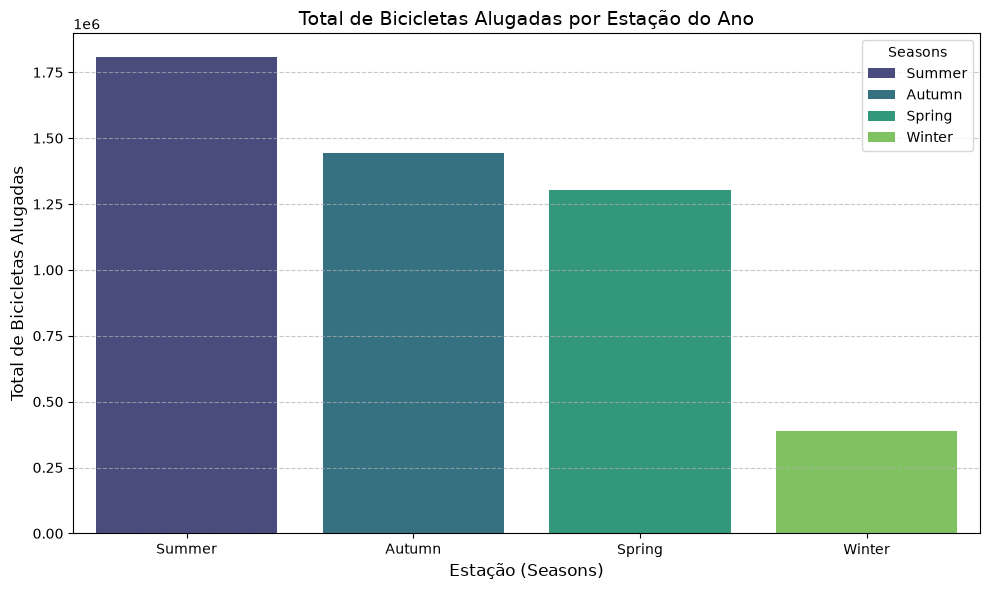

In [11]:
# Objetivo: Visualizar o total acumulado de bicicletas alugadas por estação do ano
bikes_by_season = df.groupby('Seasons')['Rented_Bike_Count'].sum().reset_index()
bikes_by_season = bikes_by_season.sort_values(by='Rented_Bike_Count', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Seasons',
    y='Rented_Bike_Count',
    data=bikes_by_season,
    palette='viridis',
    hue='Seasons',
    hue_order=['Summer', 'Autumn', 'Spring', 'Winter'],
    legend=True
)

plt.title('Total de Bicicletas Alugadas por Estação do Ano', fontsize=14)
plt.xlabel('Estação (Seasons)', fontsize=12)
plt.ylabel('Total de Bicicletas Alugadas', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [12]:
bikes_by_season

,Seasons,Rented_Bike_Count
2,Summer,1807505
0,Autumn,1442443
1,Spring,1301922
3,Winter,388590


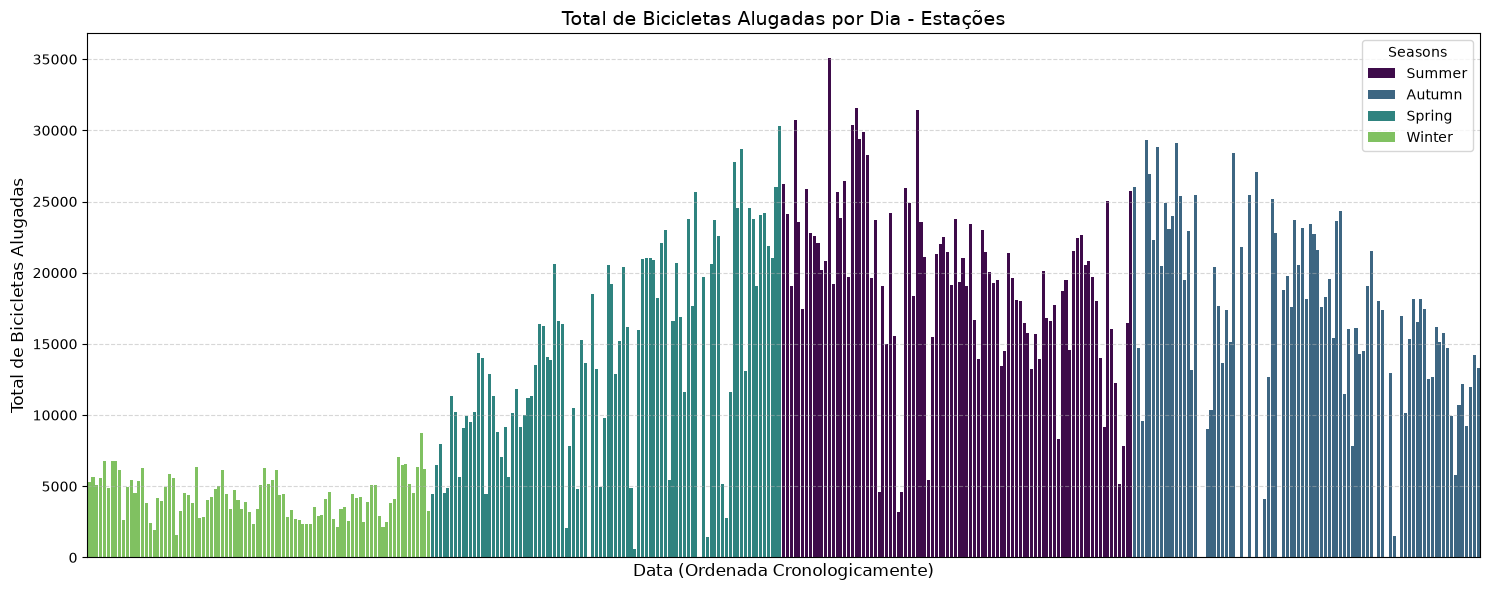

In [13]:
# Objetivo: Exibir a série temporal diária completa de aluguéis, colorida pela estação do ano
bikes_daily_season = df.groupby(['Date_Parsed', 'Seasons'])['Rented_Bike_Count'].sum().reset_index()
bikes_daily_season = bikes_daily_season.sort_values(by='Date_Parsed')

plt.figure(figsize=(15, 6))
sns.barplot(
    x='Date_Parsed',
    y='Rented_Bike_Count',
    hue='Seasons',
    hue_order=['Summer', 'Autumn', 'Spring', 'Winter'],
    data=bikes_daily_season,
    dodge=False,
    palette=fixed_season_palette
)

plt.title('Total de Bicicletas Alugadas por Dia - Estações', fontsize=14)
plt.xlabel('Data (Ordenada Cronologicamente)', fontsize=12)
plt.ylabel('Total de Bicicletas Alugadas', fontsize=12)
plt.xticks([])  # Oculta rótulos individuais de cada dia para evitar sobreposição
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### O que observamos na análise de sazonalidade

Ao analisar os gráficos de aluguel por estação e ao longo do ano, destacam-se os seguintes pontos:
- O volume de aluguéis no inverno (`Winter`) é muito menor do que nas demais estações. Andar de bicicleta no frio rigoroso de Seul provavelmente é desfavorável.
- Na série cronológica diária, observa-se uma tendência de crescimento contínuo após o término do inverno, com picos elevados no verão e no outono.
- Apesar do crescimento nas estações mais quentes, chamam a atenção várias quedas abruptas de aluguéis em dias pontuais, atingindo níveis tão baixos quanto no inverno.

A questão seguinte passa a ser: o que acontece nesses dias específicos de queda? Seriam feriados, finais de semana ou alguma paralisação do serviço?


### 4.2 Investigação de Feriados e Datas Comemorativas (`Holiday`)

Pergunta da análise: as quedas acentuadas observadas na série temporal coincidem com feriados nacionais?

Para investigar esse comportamento, realizamos uma consulta externa ao calendário de feriados de Seul durante o período da coleta (dezembro/2017 a novembro/2018):

| Data | Nome do Feriado / Celebração |
| :--- | :--- |
| `25/12/2017` | Natal |
| `01/01/2018` | Ano-Novo |
| `15/02/2018` | Véspera de Seollal |
| `16/02/2018` | Seollal / Ano-Novo Lunar |
| `17/02/2018` | Dia seguinte ao Seollal |
| `01/03/2018` | Dia do Movimento de Independência |
| `05/05/2018` | Dia das Crianças |
| `07/05/2018` | Feriado substituto do Dia das Crianças |
| `22/05/2018` | Aniversário de Buda |
| `06/06/2018` | Dia Memorial |
| `15/08/2018` | Dia da Libertação |
| `23/09/2018` | Véspera de Chuseok |
| `24/09/2018` | Chuseok / Ação de Graças |
| `25/09/2018` | Dia seguinte ao Chuseok |
| `26/09/2018` | Feriado substituto do Chuseok |
| `03/10/2018` | Dia da Fundação Nacional |
| `09/10/2018` | Dia do Hangeul |

Fonte de referência do calendário sul-coreano: https://time.is/calendar/2018/South_Korea


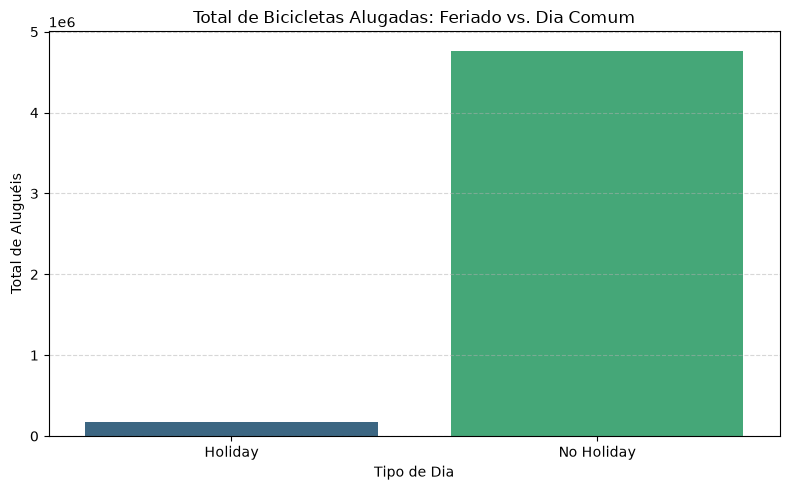

In [14]:
# Objetivo: Comparar o volume agregado de aluguéis entre feriados e dias normais
bikes_holiday_summary = df.groupby('Holiday')['Rented_Bike_Count'].sum().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x='Holiday',
    y='Rented_Bike_Count',
    data=bikes_holiday_summary,
    palette='viridis',
    hue='Holiday',
    legend=False
)
plt.title('Total de Bicicletas Alugadas: Feriado vs. Dia Comum', fontsize=12)
plt.xlabel('Tipo de Dia', fontsize=10)
plt.ylabel('Total de Aluguéis', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

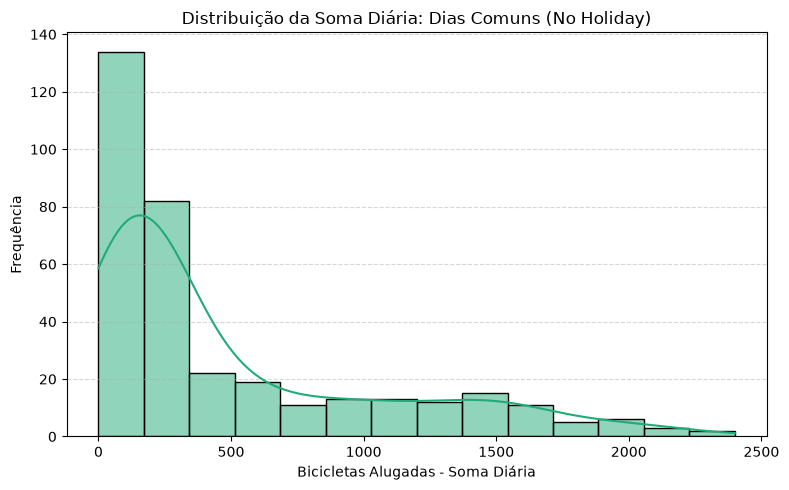

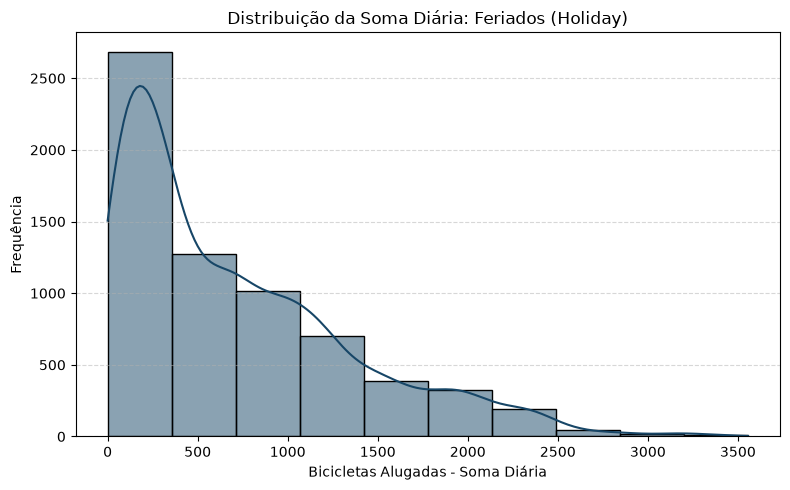

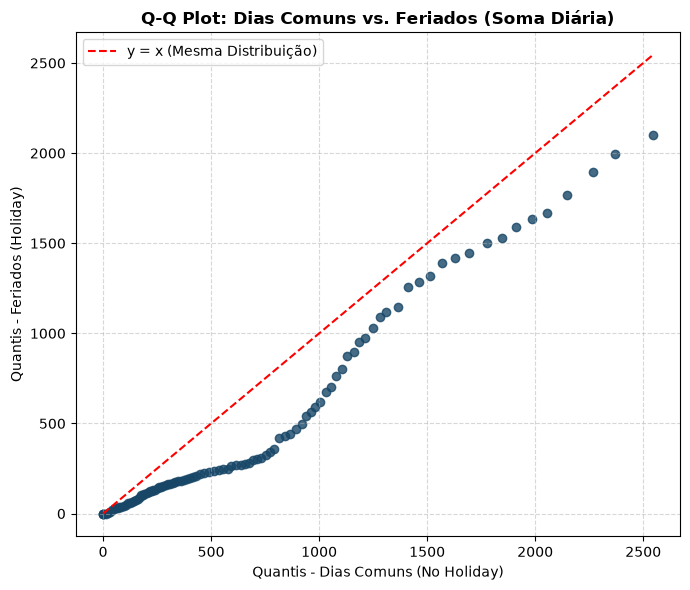

In [15]:
feriado = df[df['Holiday'] == 'Holiday']['Rented_Bike_Count']
nao_feriado = df[df['Holiday'] == 'No Holiday']['Rented_Bike_Count']

# 1. Histograma: Dias Comuns (No Holiday)
plt.figure(figsize=(8, 5))
sns.histplot(feriado, kde=True, color="#21ab78")
plt.title('Distribuição da Soma Diária: Dias Comuns (No Holiday)', fontsize=12)
plt.xlabel('Bicicletas Alugadas - Soma Diária', fontsize=10)
plt.ylabel('Frequência', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Histograma: Feriados (Holiday)
plt.figure(figsize=(8, 5))
sns.histplot(nao_feriado, kde=True, color="#174667", bins=10)
plt.title('Distribuição da Soma Diária: Feriados (Holiday)', fontsize=12)
plt.xlabel('Bicicletas Alugadas - Soma Diária', fontsize=10)
plt.ylabel('Frequência', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Q-Q Plot de duas amostras
plt.figure(figsize=(7, 6))
quantis = np.linspace(0.01, 0.99, 100)
q_nao_feriado = np.quantile(nao_feriado, quantis)
q_feriado = np.quantile(feriado, quantis)

plt.scatter(q_nao_feriado, q_feriado, color="#174667", alpha=0.8)

# Reta de referência y = x (indica se as distribuições forem idênticas)
min_val = min(q_nao_feriado.min(), q_feriado.min())
max_val = max(q_nao_feriado.max(), q_feriado.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=1.5, label='y = x (Mesma Distribuição)')

plt.title('Q-Q Plot: Dias Comuns vs. Feriados (Soma Diária)', fontsize=12, fontweight='bold')
plt.xlabel('Quantis - Dias Comuns (No Holiday)', fontsize=10)
plt.ylabel('Quantis - Feriados (Holiday)', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

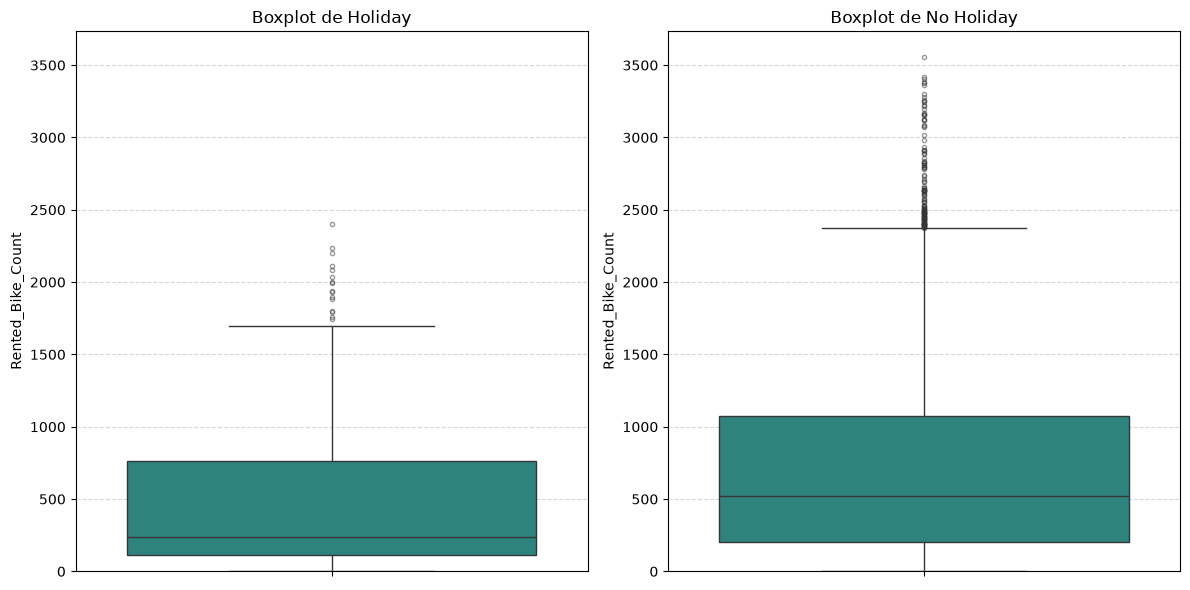

In [16]:
# Objetivo: Comparar a distribuição de bicicletas alugadas nas duas situações (dias de semana vs finais de semana) usando subplots
situacoes = ['Holiday', 'No Holiday']

plt.figure(figsize=(12, 6))
for i, sit in enumerate(situacoes, 1):
    plt.subplot(1, 2, i)
    sns.boxplot(
        y=df[df['Holiday'] == sit]['Rented_Bike_Count'],
        color='#21918c',
        flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.5}
    )
    plt.title(f'Boxplot de {sit}', fontsize=12)
    plt.ylabel('Rented_Bike_Count', fontsize=10)
    plt.ylim(0, df['Rented_Bike_Count'].max() * 1.05)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


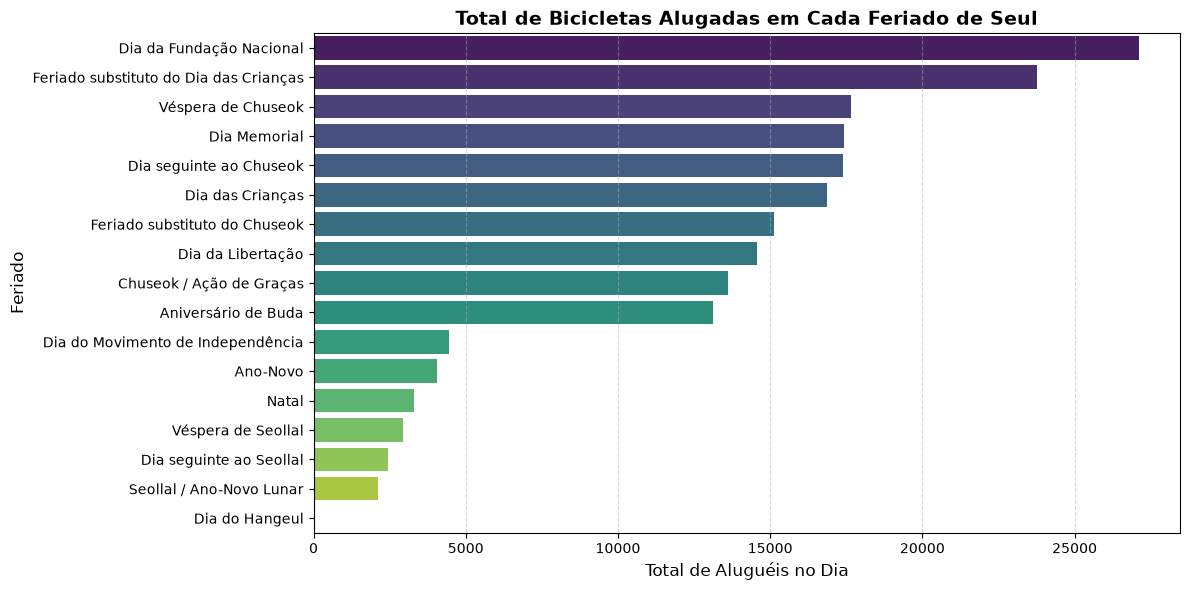

In [17]:
# Objetivo: Analisar o volume de aluguéis em cada um dos feriados específicos mapeados em Seul
feriados_mapeados = {
    '25/12/2017': 'Natal',
    '01/01/2018': 'Ano-Novo',
    '15/02/2018': 'Véspera de Seollal',
    '16/02/2018': 'Seollal / Ano-Novo Lunar',
    '17/02/2018': 'Dia seguinte ao Seollal',
    '01/03/2018': 'Dia do Movimento de Independência',
    '05/05/2018': 'Dia das Crianças',
    '07/05/2018': 'Feriado substituto do Dia das Crianças',
    '22/05/2018': 'Aniversário de Buda',
    '06/06/2018': 'Dia Memorial',
    '15/08/2018': 'Dia da Libertação',
    '23/09/2018': 'Véspera de Chuseok',
    '24/09/2018': 'Chuseok / Ação de Graças',
    '25/09/2018': 'Dia seguinte ao Chuseok',
    '26/09/2018': 'Feriado substituto do Chuseok',
    '03/10/2018': 'Dia da Fundação Nacional',
    '09/10/2018': 'Dia do Hangeul'
}

daily_rentals = df.groupby('Date')['Rented_Bike_Count'].sum().reset_index()
daily_rentals_holidays = daily_rentals[daily_rentals['Date'].isin(feriados_mapeados.keys())].copy()
daily_rentals_holidays['Nome_Feriado'] = daily_rentals_holidays['Date'].map(feriados_mapeados)
daily_rentals_holidays = daily_rentals_holidays.sort_values(by='Rented_Bike_Count', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    x='Rented_Bike_Count',
    y='Nome_Feriado',
    data=daily_rentals_holidays,
    palette='viridis',
    hue='Nome_Feriado',
    legend=False
)
plt.title('Total de Bicicletas Alugadas em Cada Feriado de Seul', fontsize=14, fontweight='bold')
plt.xlabel('Total de Aluguéis no Dia', fontsize=12)
plt.ylabel('Feriado', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### O que observamos na análise de feriados

A comparação entre feriados e dias comuns gerou observações relevantes:
- O total geral de aluguéis em feriados é muito menor simplesmente porque existem poucos feriados no ano.
- Quando olhamos os feriados individualmente, muitos deles registram grande quantidade de aluguéis, especialmente nos meses mais quentes (como no Dia da Libertação, Dia Memorial e Dia das Crianças).
- A distribuição é relativamente semelhante, apesar de ser feriado implicar em valores um pouco menores
- Portanto, o fato de ser feriado não reduz a demanda necessariamente e não explica os dias de queda drástica observados na série temporal.

Isso nos leva a testar a próxima hipótese: será que o tipo de dia (dia útil versus final de semana) explica essas variações?


### 4.3 Investigação de Dias Úteis vs. Finais de Semana (`Day_Type`)

Pergunta da análise: o padrão de uso em dias de semana é diferente do final de semana, a ponto de explicar quedas bruscas de aluguel?

### Justificativa – Criação das Variáveis de Tipo de Dia
A partir de `Date_Parsed`, derivamos `Day_of_Week` (0 = Segunda, ..., 6 = Domingo) e agrupamos em `Day_Type` (`Weekday` para dias úteis e `Weekend` para finais de semana). A intenção é verificar se o propósito de locomoção (deslocamento para trabalho/estudo versus lazer) gera um comportamento de demanda muito diferente.


In [18]:
# Objetivo: Criar features de dia da semana e classificar em dia útil (Weekday) ou final de semana (Weekend)
df['Day_of_Week'] = df['Date_Parsed'].dt.dayofweek
df['Day_Type'] = df['Day_of_Week'].apply(lambda x: 'Weekend' if x >= 5 else 'Weekday')

print("Distribuição dos registros horários por Tipo de Dia:")
print(df['Day_Type'].value_counts())
print("\nAmostra das variáveis temporais criadas:")
df[['Date_Parsed', 'Day_of_Week', 'Day_Type']].drop_duplicates().sort_values(by='Date_Parsed').head(7)

Distribuição dos registros horários por Tipo de Dia:
Day_Type
Weekday    4995
Weekend    2013
Name: count, dtype: int64

Amostra das variáveis temporais criadas:


/tmp/ipykernel_132681/3272931219.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['Day_of_Week'] = df['Date_Parsed'].dt.dayofweek


,Date_Parsed,Day_of_Week,Day_Type
0,2017-12-01,4,Weekday
15,2017-12-02,5,Weekend
29,2017-12-03,6,Weekend
47,2017-12-04,0,Weekday
63,2017-12-05,1,Weekday
83,2017-12-06,2,Weekday
100,2017-12-07,3,Weekday


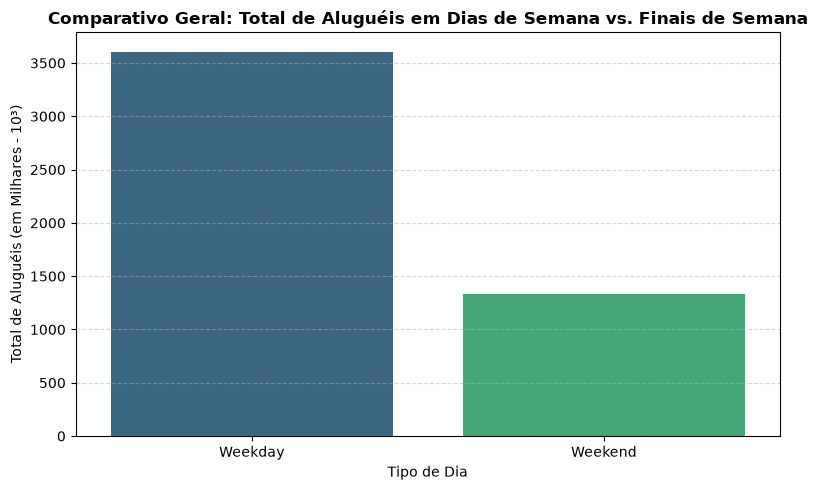

In [19]:
# Objetivo: Comparar o total acumulado de aluguéis entre dias de semana e finais de semana
total_by_day_type = df.groupby('Day_Type')['Rented_Bike_Count'].sum().reset_index()
total_by_day_type['Total_K'] = total_by_day_type['Rented_Bike_Count'] / 1000

plt.figure(figsize=(8, 5))
sns.barplot(
    x='Day_Type',
    y='Total_K',
    data=total_by_day_type,
    palette='viridis',
    hue='Day_Type',
    legend=False
)
plt.title('Comparativo Geral: Total de Aluguéis em Dias de Semana vs. Finais de Semana', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Dia', fontsize=10)
plt.ylabel('Total de Aluguéis (em Milhares - 10³)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

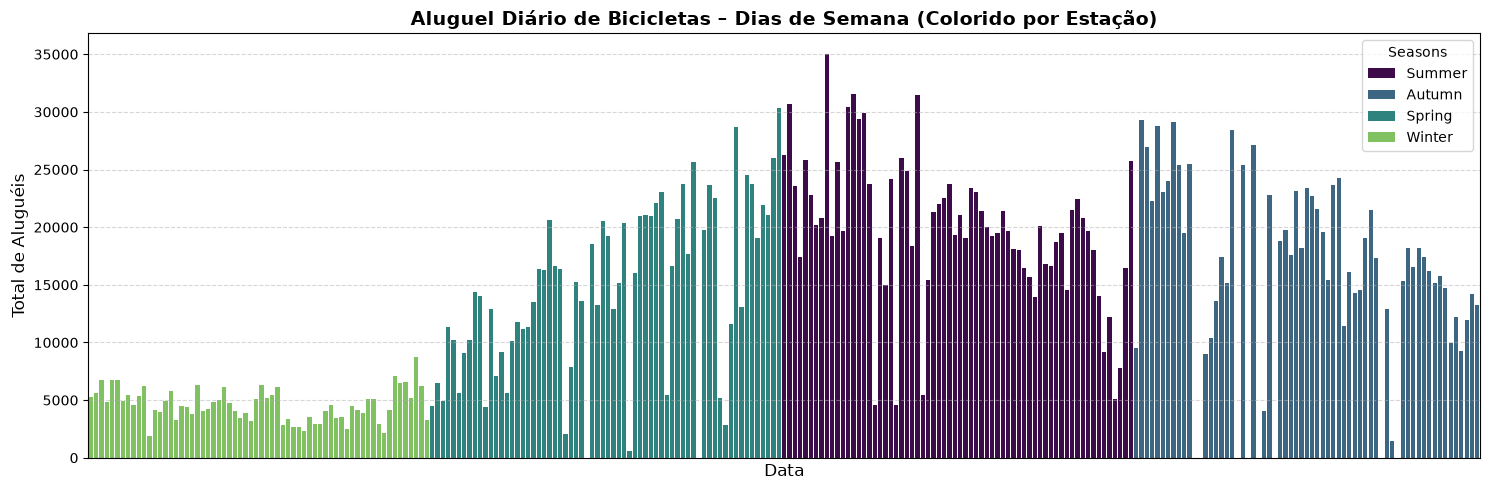

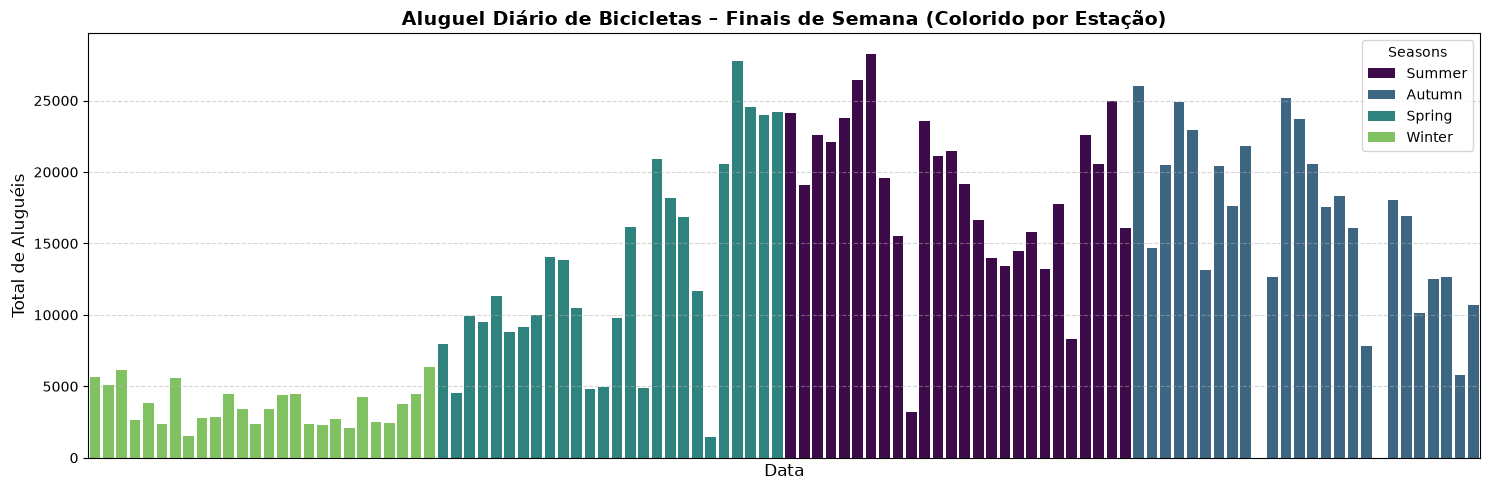

In [20]:
# Objetivo: Comparar as séries temporais de dias de semana e finais de semana separadamente
daily_summary = df.groupby(['Date_Parsed', 'Day_Type', 'Seasons'])['Rented_Bike_Count'].sum().reset_index()

weekdays_data = daily_summary[daily_summary['Day_Type'] == 'Weekday'].sort_values(by='Date_Parsed')
weekends_data = daily_summary[daily_summary['Day_Type'] == 'Weekend'].sort_values(by='Date_Parsed')

plt.figure(figsize=(15, 5))
sns.barplot(
    x='Date_Parsed',
    y='Rented_Bike_Count',
    hue='Seasons',
    hue_order=['Summer', 'Autumn', 'Spring', 'Winter'],
    data=weekdays_data,
    dodge=False,
    palette=fixed_season_palette
)
plt.title('Aluguel Diário de Bicicletas – Dias de Semana (Colorido por Estação)', fontsize=14, fontweight='bold')
plt.xlabel('Data', fontsize=12)
plt.ylabel('Total de Aluguéis', fontsize=12)
plt.xticks([])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
sns.barplot(
    x='Date_Parsed',
    y='Rented_Bike_Count',
    hue='Seasons',
    hue_order=['Summer', 'Autumn', 'Spring', 'Winter'],
    data=weekends_data,
    dodge=False,
    palette=fixed_season_palette
)
plt.title('Aluguel Diário de Bicicletas – Finais de Semana (Colorido por Estação)', fontsize=14, fontweight='bold')
plt.xlabel('Data', fontsize=12)
plt.ylabel('Total de Aluguéis', fontsize=12)
plt.xticks([])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

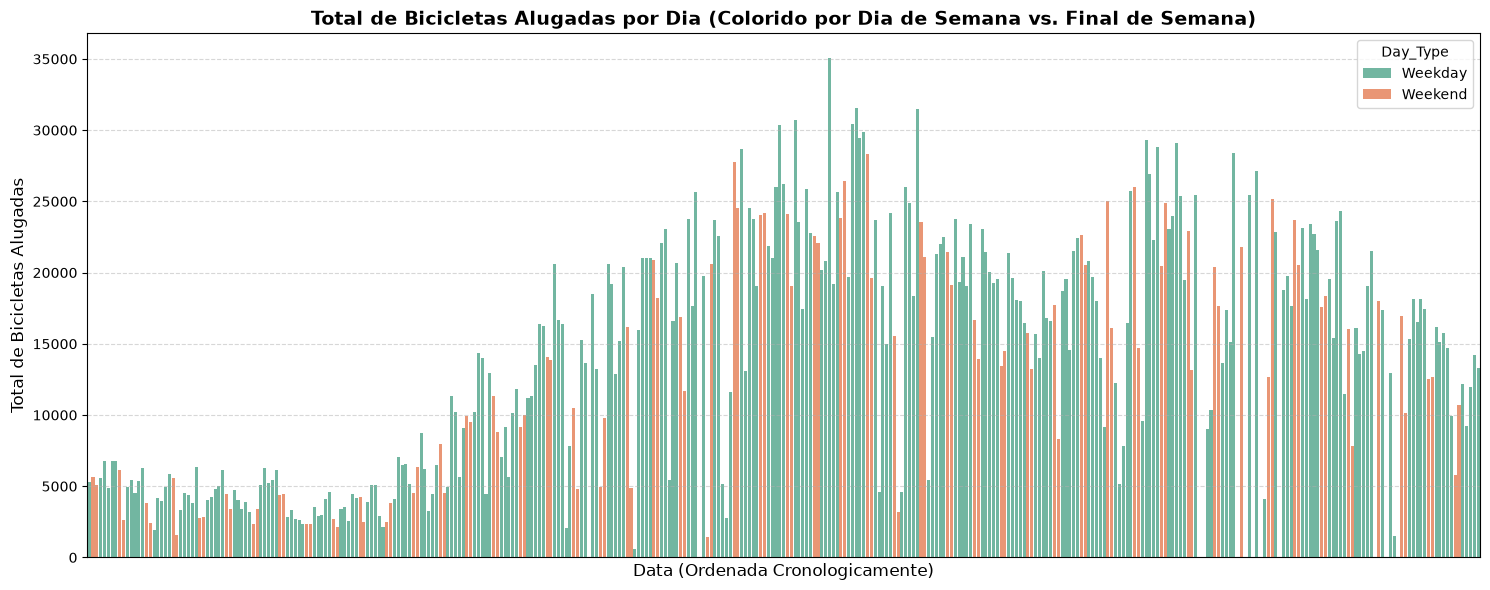

In [21]:
# Objetivo: Exibir a série temporal diária completa diferenciando dias de semana e finais de semana
bikes_daily_daytype = df.groupby(['Date_Parsed', 'Day_Type'])['Rented_Bike_Count'].sum().reset_index()
bikes_daily_daytype = bikes_daily_daytype.sort_values(by='Date_Parsed')

plt.figure(figsize=(15, 6))
sns.barplot(
    x='Date_Parsed',
    y='Rented_Bike_Count',
    hue='Day_Type',
    hue_order=['Weekday', 'Weekend'],
    data=bikes_daily_daytype,
    dodge=False,
    palette='Set2'
)

plt.title('Total de Bicicletas Alugadas por Dia (Colorido por Dia de Semana vs. Final de Semana)', fontsize=14, fontweight='bold')
plt.xlabel('Data (Ordenada Cronologicamente)', fontsize=12)
plt.ylabel('Total de Bicicletas Alugadas', fontsize=12)
plt.xticks([])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

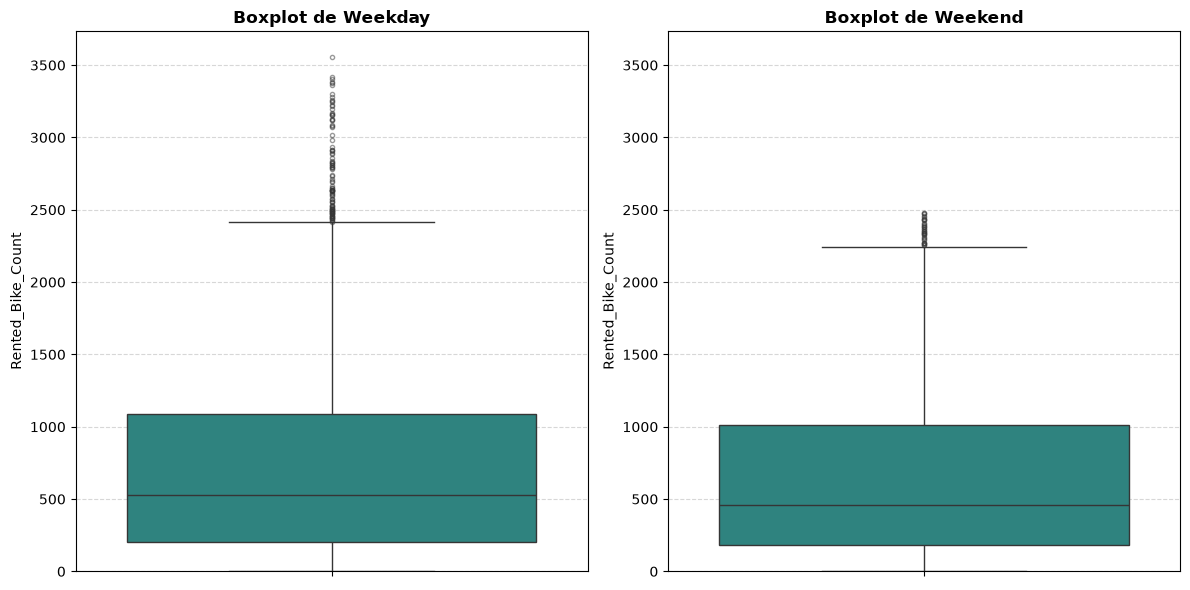

In [22]:
# Objetivo: Comparar a distribuição de bicicletas alugadas nas duas situações (dias de semana vs finais de semana) usando subplots
situacoes = ['Weekday', 'Weekend']

plt.figure(figsize=(12, 6))
for i, sit in enumerate(situacoes, 1):
    plt.subplot(1, 2, i)
    sns.boxplot(
        y=df[df['Day_Type'] == sit]['Rented_Bike_Count'],
        color='#21918c',
        flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.5}
    )
    plt.title(f'Boxplot de {sit}', fontsize=12, fontweight='bold')
    plt.ylabel('Rented_Bike_Count', fontsize=10)
    plt.ylim(0, df['Rented_Bike_Count'].max() * 1.05)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### O que observamos na análise de dias úteis e finais de semana

A decomposição temporal entre dias úteis e finais de semana mostra que:
- Dias de semana acumulam maior volume total porque representam 5 dos 7 dias da semana.
- Contudo, na série temporal cronológica, a trajetória de aluguéis em dias úteis e finais de semana é muito parecida, com quedas acentuadas ocorrendo simultaneamente em ambos.
- Isso indica que o tipo de dia não é a causa das quedas pontuais de aluguel. A explicação parece estar ligada a características específicas daquele dia (como eventos climáticos), e não ao calendário em si.

Antes de passarmos para as variáveis de clima, resta checar um último fator de calendário e operação: o funcionamento do sistema.


### 4.4 Status de Operação do Sistema (`Functioning_Day`)

Pergunta da análise: as datas com contagem de aluguéis próxima ou igual a zero decorrem de indisponibilidade operacional do próprio sistema?


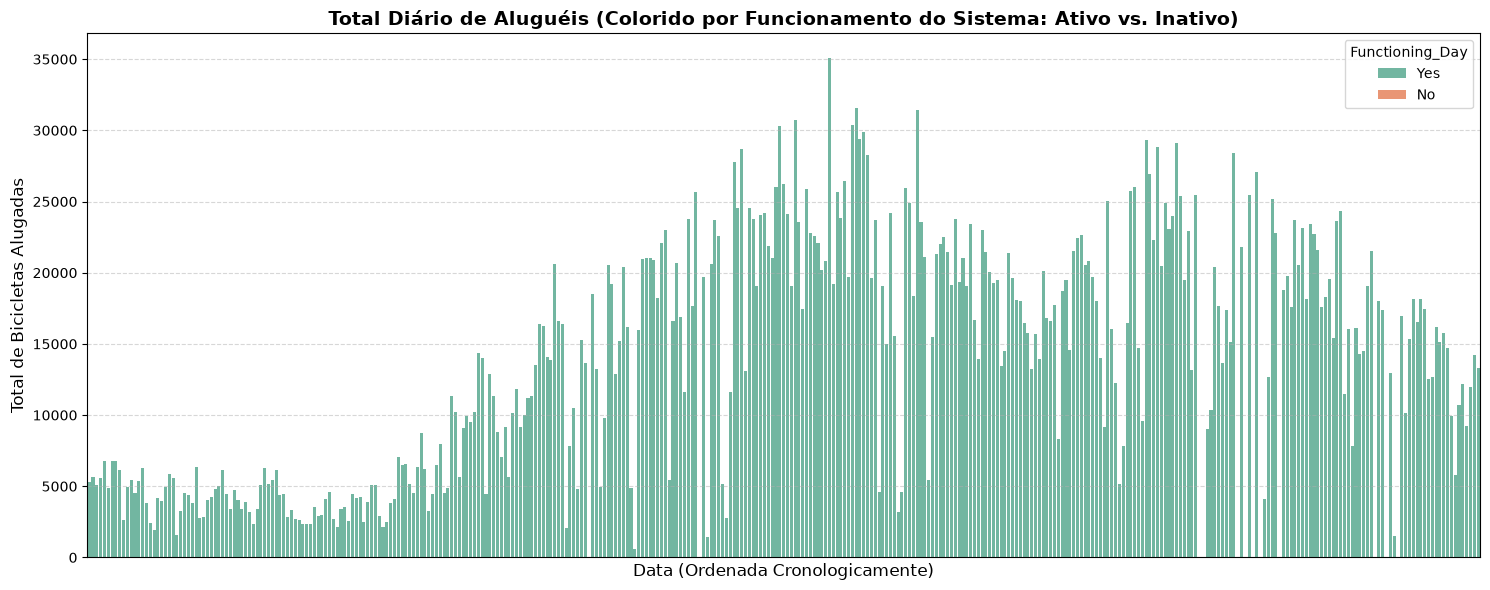

In [23]:
# Objetivo: Visualizar a série temporal de aluguéis destacando dias com sistema ativo versus inativo
bikes_daily_functioning = df.groupby(['Date_Parsed', 'Functioning_Day'])['Rented_Bike_Count'].sum().reset_index()
bikes_daily_functioning = bikes_daily_functioning.sort_values(by='Date_Parsed')

plt.figure(figsize=(15, 6))
sns.barplot(
    x='Date_Parsed',
    y='Rented_Bike_Count',
    hue='Functioning_Day',
    hue_order=['Yes', 'No'],
    data=bikes_daily_functioning,
    dodge=False,
    palette='Set2'
)

plt.title('Total Diário de Aluguéis (Colorido por Funcionamento do Sistema: Ativo vs. Inativo)', fontsize=14, fontweight='bold')
plt.xlabel('Data (Ordenada Cronologicamente)', fontsize=12)
plt.ylabel('Total de Bicicletas Alugadas', fontsize=12)
plt.xticks([])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [24]:
# Objetivo: Inspecionar os registros onde o sistema esteve inativo (Functioning_Day == 'No')
dias_inativos = bikes_daily_functioning[bikes_daily_functioning["Functioning_Day"] == "No"]
print(f"Total de datas com registro de inatividade: {len(dias_inativos)}")
dias_inativos

Total de datas com registro de inatividade: 13


,Date_Parsed,Functioning_Day,Rented_Bike_Count
131,2018-04-11,No,0
160,2018-05-10,No,0
291,2018-09-18,No,0
292,2018-09-19,No,0
301,2018-09-28,No,0
303,2018-09-30,No,0
305,2018-10-02,No,0
307,2018-10-04,No,0
309,2018-10-06,No,0
313,2018-10-09,No,0


### O que observamos e transição para as variáveis numéricas

A verificação do funcionamento do sistema trouxe uma resposta direta para parte dos dados:
- Em todos os dias em que o sistema esteve inativo (`Functioning_Day == 'No'`), a contagem de aluguéis é estritamente zero (`Rented_Bike_Count == 0`). Isso explica totalmente vários pontos nulos encontrados na série temporal.
- Com isso, o comportamento do calendário e da operação fica delimitado: o inverno reduz o volume geral de aluguéis, feriados têm demanda variável conforme a época do ano, dias de semana e fins de semana têm dinâmicas parecidas, e dias sem funcionamento têm aluguel nulo.
- A pergunta central que segue aberta é: o que faz a demanda despencar em dias normais de funcionamento (`Functioning_Day == 'Yes'`), inclusive durante as estações quentes?

A resposta provável reside nas variáveis numéricas e meteorológicas (chuva, neve, umidade elevada, vento e temperaturas extremas). A próxima etapa da análise exploratória será dedicada a investigar essas variáveis contínuas e sua relação com a demanda.


## Seção 5 – Análise Exploratória: Distribuição das Variáveis Numéricas e Outliers

Na seção anterior, vimos que o inverno reduz o volume geral de aluguéis e que dias sem funcionamento do sistema zeram a demanda, mas restou a pergunta: o que explica as quedas acentuadas de aluguéis em dias normais de funcionamento, inclusive durante as estações quentes?

Para responder a essa pergunta, precisamos analisar as variáveis contínuas e meteorológicas. Investigamos a distribuição de cada variável numérica para entender sua assimetria, concentração e identificar possíveis outliers.

As variáveis numéricas sob análise são:
- Variável resposta: `Rented_Bike_Count`
- Variáveis meteorológicas: `Temperature`, `Humidity`, `Wind_Speed`, `Visibility`, `Dew_Point_Temperature`, `Solar_Radiation`, `Rainfall`, `Snowfall`


### 5.1 Histogramas e Formato das Distribuições

Pergunta da análise: qual é o formato da distribuição das variáveis numéricas e quais apresentam assimetria ou concentração excessiva em zero?


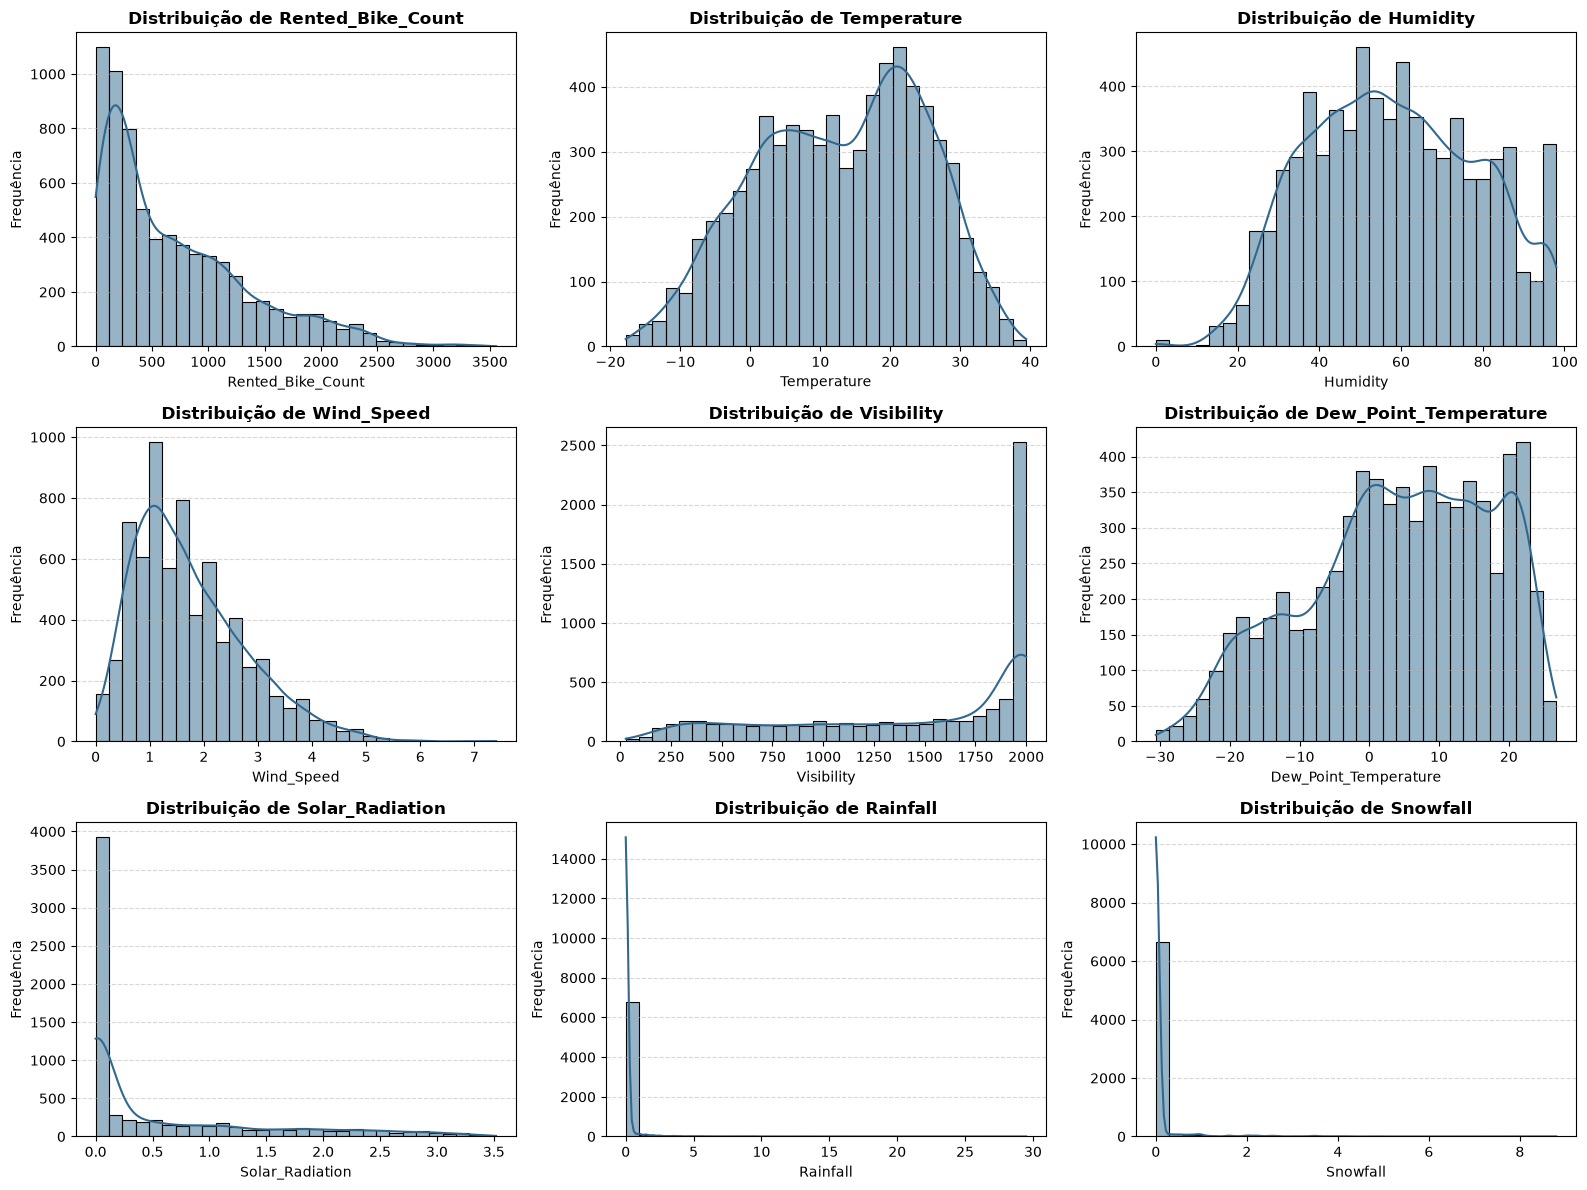

In [25]:
# Objetivo: Plotar histogramas com KDE para visualizar o formato da distribuição das variáveis numéricas
cols_numericas = [
    'Rented_Bike_Count', 'Temperature', 'Humidity', 'Wind_Speed',
    'Visibility', 'Dew_Point_Temperature', 'Solar_Radiation', 'Rainfall', 'Snowfall'
]

plt.figure(figsize=(16, 12))
for i, col in enumerate(cols_numericas, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[col], kde=True, color='#31688e', bins=30)
    plt.title(f'Distribuição de {col}', fontsize=12, fontweight='bold')
    plt.xlabel(col, fontsize=10)
    plt.ylabel('Frequência', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### O que observei nos histogramas

Pelos gráficos de distribuição fico com a suspeita de que `Visibility`, `Solar_Radiation`, `Rainfall` e `Snowfall` tenham outliers. É claro que isso pode fazer parte do comportamento comum dos dados. Como o caso do `Snowfall`: em Seul, a neve acontece basicamente em um único período do ano (no inverno, de dezembro a fevereiro), com pico mais provável de fim de dezembro até o início de fevereiro, especialmente em janeiro.

Fonte de referência sobre o clima de Seul: https://english.visitseoul.net/essential-Info-article/Climate/ENN000385


### 5.2 Boxplots e Identificação de Outliers

Pergunta da análise: quais variáveis apresentam valores atípicos (outliers) pelo critério estatístico do IQR e qual é o significado prático desses valores?


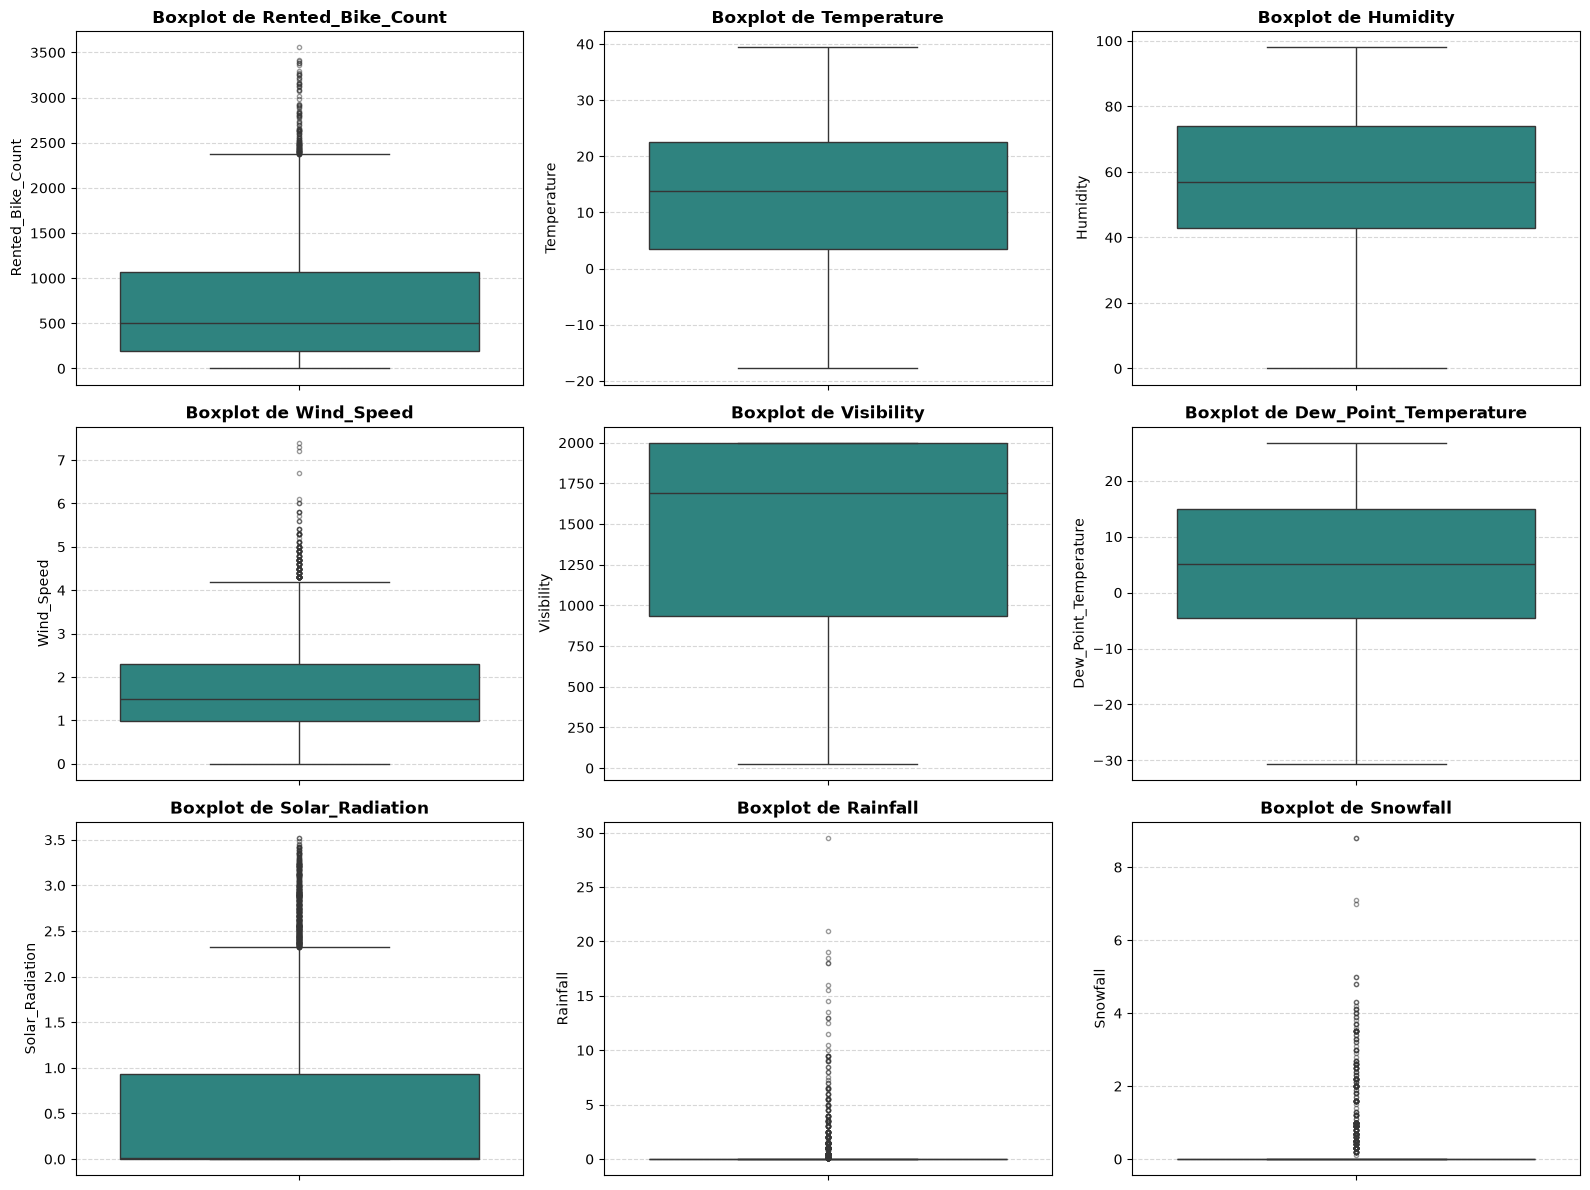

In [26]:
# Objetivo: Plotar boxplots para identificar a dispersão e presença de outliers nas variáveis numéricas
plt.figure(figsize=(16, 12))
for i, col in enumerate(cols_numericas, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col], color='#21918c', flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.5})
    plt.title(f'Boxplot de {col}', fontsize=12, fontweight='bold')
    plt.ylabel(col, fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### O que observei nos boxplots

A maioria dos gráficos aparenta ter um comportamento esperado, com exceção de `Solar_Radiation`, `Rainfall`, `Snowfall` e `Wind_Speed` que estão bem atípicos. Possivelmente eles estão diretamente correlacionados aos indicadores de chuva e neve. Seul fica em uma zona temperada com estações bem definidas: se só chover em um mês lá, qualquer indício de chuva vira outlier. Para isso vou investigar melhor esse comportamento dos dados com relação às estações.


### 5.3 Série Temporal das Condições Meteorológicas e Estações do Ano

Pergunta da análise: como a radiação solar, a chuva, a neve e a velocidade do vento se distribuem ao longo do ano e de que forma esses eventos se concentram nas diferentes estações?


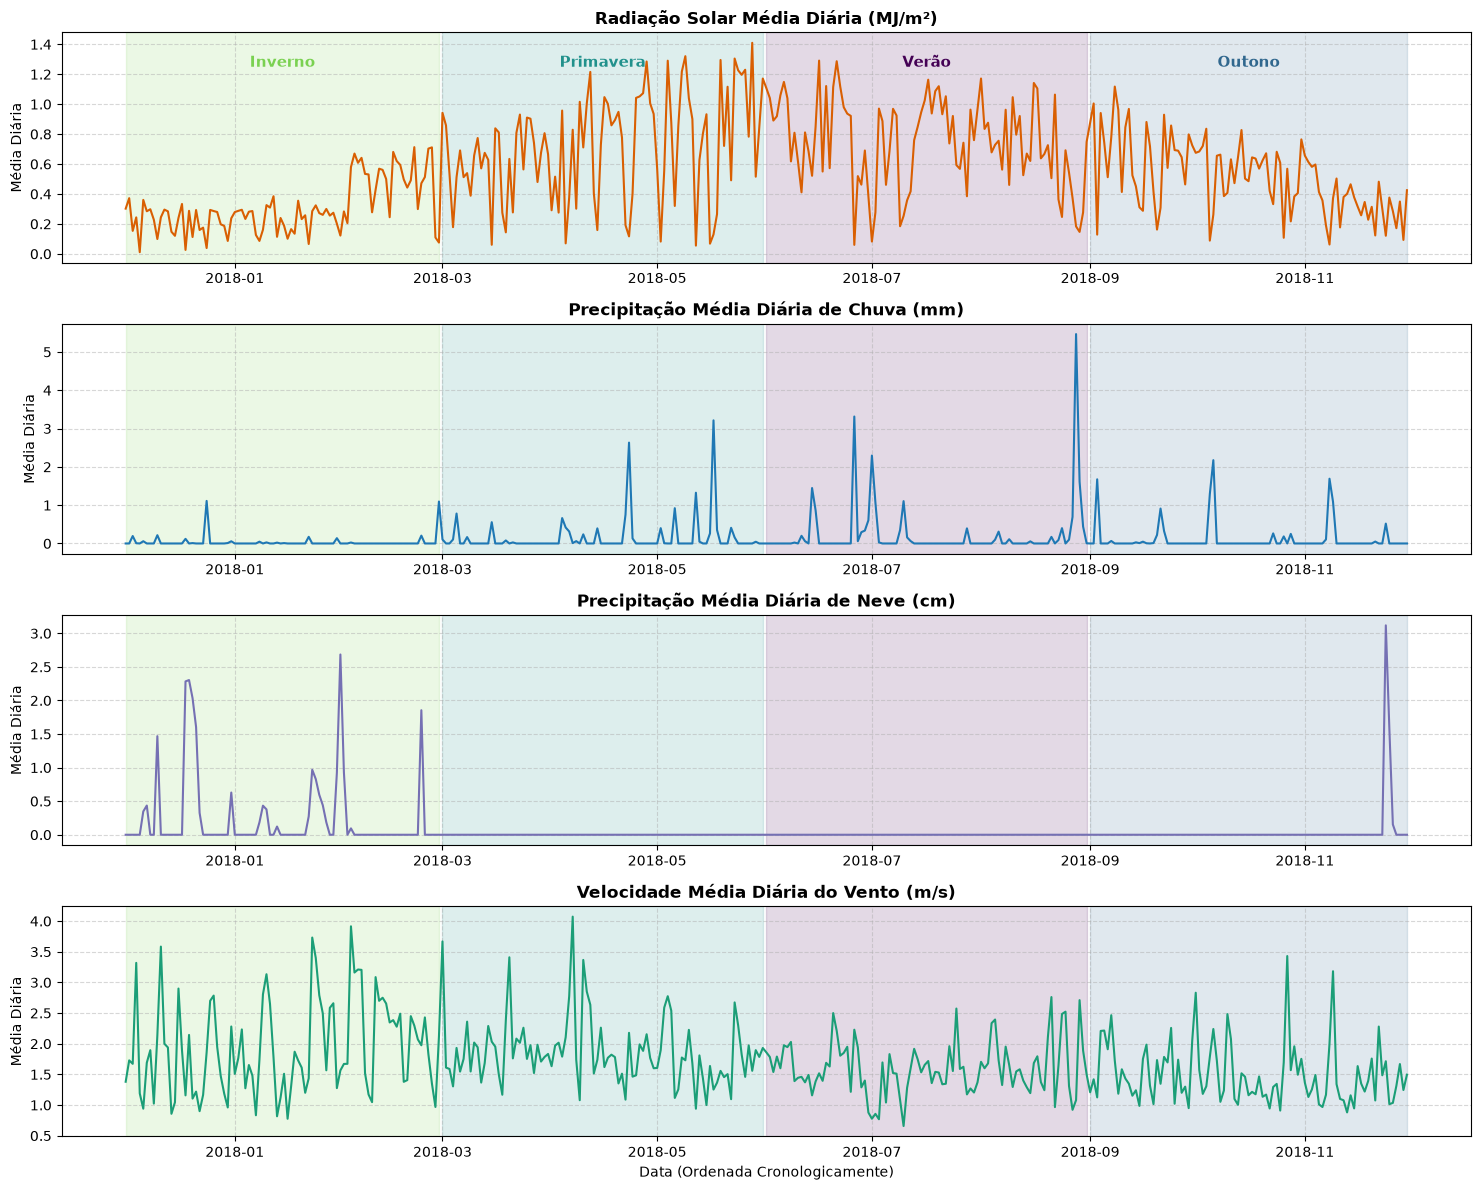

In [27]:
# Objetivo: Plotar 4 gráficos temporais individuais para cada variável meteorológica com destaque das estações
daily_weather = df.groupby('Date_Parsed')[['Solar_Radiation', 'Rainfall', 'Snowfall', 'Wind_Speed']].mean().reset_index()

metricas = [
    ('Solar_Radiation', 'Radiação Solar Média Diária (MJ/m²)', '#d95f02'),
    ('Rainfall', 'Precipitação Média Diária de Chuva (mm)', '#1f78b4'),
    ('Snowfall', 'Precipitação Média Diária de Neve (cm)', '#7570b3'),
    ('Wind_Speed', 'Velocidade Média Diária do Vento (m/s)', '#1b9e77')
]

season_ranges = [
    ('Inverno', pd.Timestamp('2017-12-01'), pd.Timestamp('2018-02-28'), '#7ad151'),
    ('Primavera', pd.Timestamp('2018-03-01'), pd.Timestamp('2018-05-31'), '#21918c'),
    ('Verão', pd.Timestamp('2018-06-01'), pd.Timestamp('2018-08-31'), '#440154'),
    ('Outono', pd.Timestamp('2018-09-01'), pd.Timestamp('2018-11-30'), '#31688e')
]

plt.figure(figsize=(15, 12))

for idx, (col, rotulo, cor) in enumerate(metricas, 1):
    plt.subplot(4, 1, idx)
    
    # Destaque das estações com axvspan
    for nome, start, end, cor_estacao in season_ranges:
        plt.axvspan(start, end, color=cor_estacao, alpha=0.15)
        if idx == 1:
            mid_date = start + (end - start) / 2
            plt.text(mid_date, 1.25, nome, horizontalalignment='center', 
                     fontsize=11, fontweight='bold', color=cor_estacao)
            
    plt.plot(daily_weather['Date_Parsed'], daily_weather[col], color=cor, linewidth=1.5)
    plt.title(rotulo, fontsize=12, fontweight='bold')
    plt.xlabel('Data (Ordenada Cronologicamente)' if idx == 4 else '', fontsize=10)
    plt.ylabel('Média Diária', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### O que observei na série temporal meteorológica
A unica coisa que consigo observar é que a neve é bem concentrada no inverno e que a chuva é relativamente distribuida entre primavera e inverno. Ainda não foi o suficiente para que eu consiga analisar porque existem dias em que temos poucos aluguéis


## Seção 6 – Matrizes de Correlação entre as Variáveis Numéricas

Pergunta da análise: qual o grau de associação linear (Pearson) e monotônica (Spearman) entre as variáveis contínuas, variáveis de tempo e a demanda por bicicletas (`Rented_Bike_Count`)?


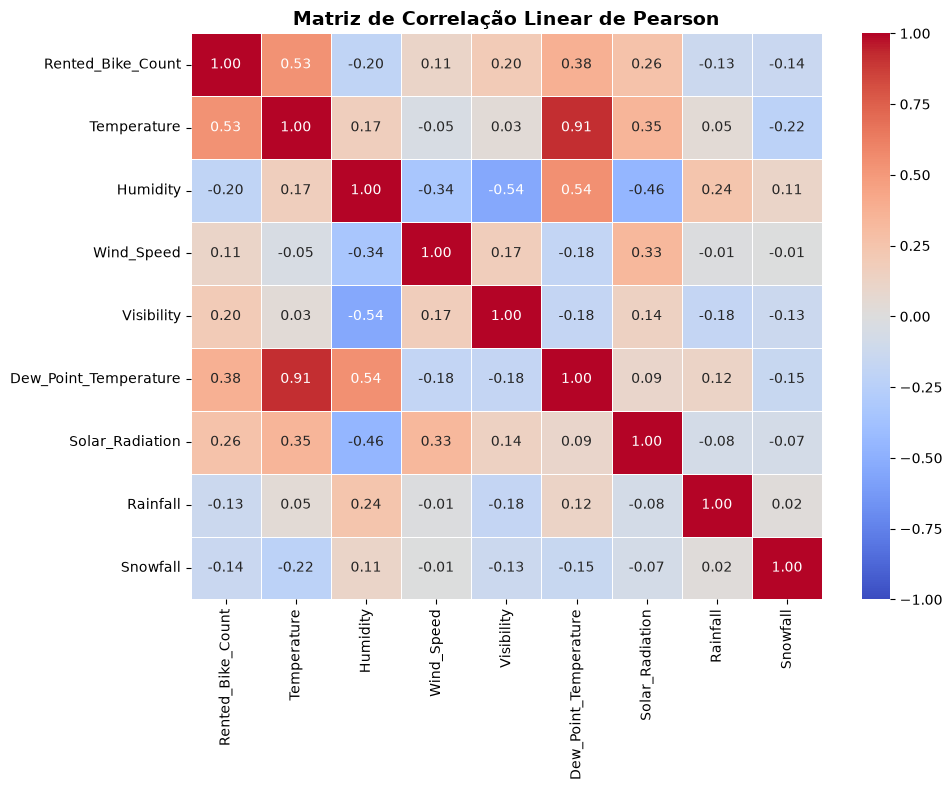

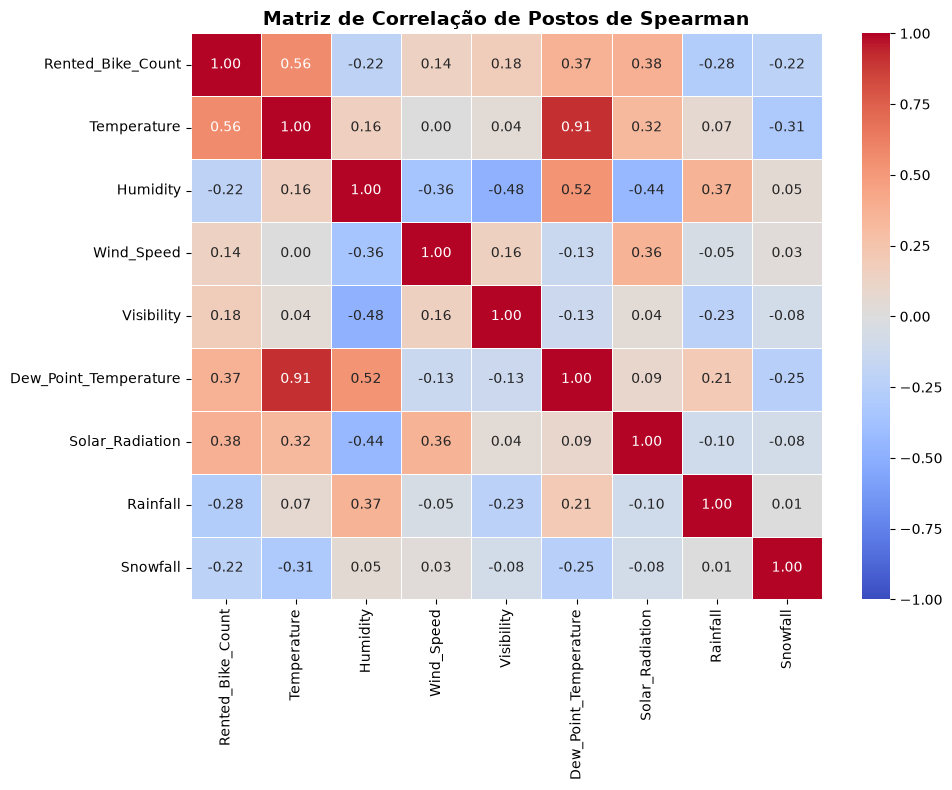

In [28]:
# Objetivo: Plotar mapas de calor de correlação linear (Pearson) e monotônica por postos (Spearman)
cols_analise_corr = [
    'Rented_Bike_Count', 'Temperature', 'Humidity', 'Wind_Speed',
    'Visibility', 'Dew_Point_Temperature', 'Solar_Radiation', 'Rainfall', 'Snowfall'
]

# 1. Mapa de Calor - Correlação Linear de Pearson
plt.figure(figsize=(10, 8))
corr_pearson = df[cols_analise_corr].corr(method='pearson')
sns.heatmap(corr_pearson, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação Linear de Pearson', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Mapa de Calor - Correlação Monotônica de Spearman
plt.figure(figsize=(10, 8))
corr_spearman = df[cols_analise_corr].corr(method='spearman')
sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação de Postos de Spearman', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### O que observei nas matrizes de correlação

Todas as variaveis tem alguma relação com a quantidade de bicicletas alugadas, vale destacar a temperatura que tem a maior correlação. Tudo indica que temperaturas baixas (inverno e a correlçaõ postiva) implicam em menos alugueis. Mas um ponto de destaque muito importante, temos várias variaveis relacionadas com os alugueis, isso implica que a combinação de vários fatores é que vai determinar se uma bicicleta vai ser alugada (analisando por dia).


## Seção 7 – Comparação de Distribuições: Amostra do Percentil 15% vs. População Geral

Vou isolar os dias de menor demanda (vendas $\le$ percentil 15) para analisar o perfil estatístico das variáveis numéricas e avaliar a variabilidade do grupo. O objetivo é identificar padrões que expliquem a queda nas vendas e entender as causas de baixo rendimento. Em seguida, farei uma análise horária para mapear os horários de pico e os fatores que impactam a locação de bikes ao longo do dia.

Pergunta da análise: as variáveis meteorológicas nos dias de demanda extrema baixa (15% menores aluguéis diários) seguem a mesma distribuição da população geral ou exibem comportamentos marcadamente distintos?


In [40]:
# Objetivo: Filtrar a subamostra referente aos 15% menores totais diários de aluguéis e inspecionar com info() e describe()
# 1. Agrupamento diário com soma de aluguéis e médias meteorológicas
df_diario = df.groupby('Date_Parsed').agg({
    'Rented_Bike_Count': 'sum',
    'Temperature': 'mean',
    'Humidity': 'mean',
    'Wind_Speed': 'mean',
    'Visibility': 'mean',
    'Dew_Point_Temperature': 'mean',
    'Solar_Radiation': 'mean',
    'Rainfall': 'mean',
    'Snowfall': 'mean'
}).reset_index().rename(columns={'Rented_Bike_Count': 'Total_Bikes_Dia'})

# 2. Determinação do limiar do percentil 15%
limiar_p15 = df_diario['Total_Bikes_Dia'].quantile(0.15)
print(f"Limiar do Percentil 15% (Total de Aluguéis Diários): {limiar_p15:.2f}")

# 3. Divisão entre amostra de baixa demanda (P15) e a população geral
amostra_p15 = df_diario[df_diario['Total_Bikes_Dia'] <= limiar_p15].reset_index(drop=True)
populacao = df_diario.reset_index(drop=True)

print(f"Total de dias na amostra (P15): {len(amostra_p15)}")
print(f"Total de dias na população geral: {len(populacao)}\n")

print("--- INFO DA AMOSTRA (P15) ---")
amostra_p15.info()

print("\n--- DESCRIBE DA AMOSTRA (P15) ---")
display(amostra_p15.describe())


Limiar do Percentil 15% (Total de Aluguéis Diários): 3930.20
Total de dias na amostra (P15): 55
Total de dias na população geral: 365

--- INFO DA AMOSTRA (P15) ---
<class 'pandas.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Date_Parsed            55 non-null     datetime64[us]
 1   Total_Bikes_Dia        55 non-null     int64         
 2   Temperature            55 non-null     float64       
 3   Humidity               55 non-null     float64       
 4   Wind_Speed             55 non-null     float64       
 5   Visibility             55 non-null     float64       
 6   Dew_Point_Temperature  55 non-null     float64       
 7   Solar_Radiation        55 non-null     float64       
 8   Rainfall               55 non-null     float64       
 9   Snowfall               55 non-null     float64       
dtypes: datetime64[us](1), float64(

,Date_Parsed,Total_Bikes_Dia,Temperature,Humidity,Wind_Speed,Visibility,Dew_Point_Temperature,Solar_Radiation,Rainfall,Snowfall
count,55,55.000000,55.000000,55.000000,55.000000,55.000000,55.000000,55.000000,55.000000,55.000000
mean,2018-03-28 06:06:32.727272,2173.727273,1.652981,54.794324,2.033570,1479.776670,-7.363307,0.366202,0.284967,0.215961
min,2017-12-10 00:00:00,0.000000,-14.840000,25.789474,0.777273,208.500000,-28.060000,0.026316,0.000000,0.000000
25%,2018-01-13 12:00:00,1478.500000,-6.374423,39.111111,1.302632,1078.271645,-19.212762,0.127817,0.000000,0.000000
50%,2018-02-05 00:00:00,2536.000000,-0.722222,52.722222,2.050000,1793.238095,-10.045000,0.309091,0.000000,0.000000
75%,2018-05-11 00:00:00,3236.500000,11.846779,66.557018,2.680000,1940.431818,5.908824,0.574524,0.042460,0.047500
max,2018-11-09 00:00:00,3914.000000,22.081818,95.809524,3.915000,1999.562500,20.836364,1.039474,3.214286,2.685000
std,NaN,1328.441268,10.932990,19.070873,0.825659,544.880752,13.538326,0.253860,0.701728,0.539494


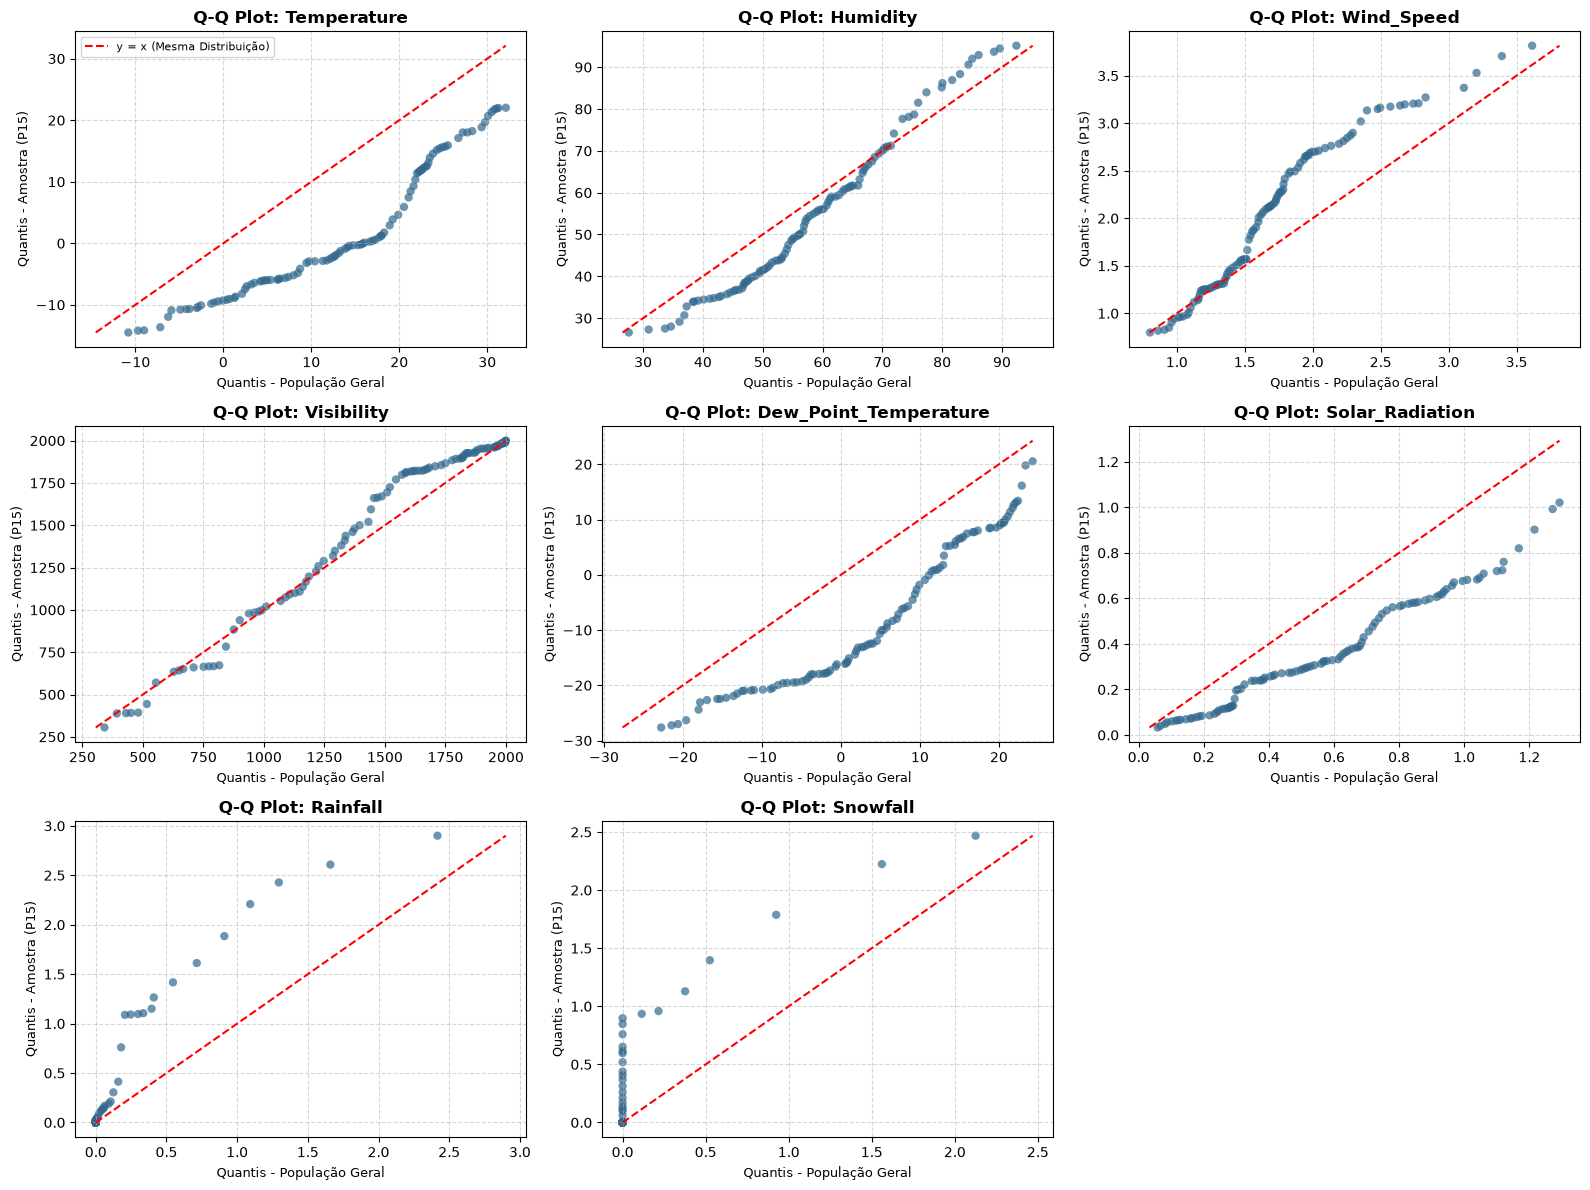

In [41]:
# Objetivo: Plotar gráficos Q-Q de duas amostras comparando a distribuição da amostra P15 com a população geral
cols_clima = [
    'Temperature', 'Humidity', 'Wind_Speed', 'Visibility',
    'Dew_Point_Temperature', 'Solar_Radiation', 'Rainfall', 'Snowfall'
]

quantis = np.linspace(0.01, 0.99, 100)

plt.figure(figsize=(16, 12))
for i, col in enumerate(cols_clima, 1):
    plt.subplot(3, 3, i)
    
    q_pop = np.quantile(populacao[col], quantis)
    q_p15 = np.quantile(amostra_p15[col], quantis)
    
    # Dispersão dos quantis correspondentes
    plt.scatter(q_pop, q_p15, color='#31688e', alpha=0.7, edgecolors='none')
    
    # Reta de referência y = x (indica distribuição idêntica entre amostra e população)
    min_val = min(q_pop.min(), q_p15.min())
    max_val = max(q_pop.max(), q_p15.max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=1.5, label='y = x (Mesma Distribuição)')
    
    plt.title(f'Q-Q Plot: {col}', fontsize=12, fontweight='bold')
    plt.xlabel('Quantis - População Geral', fontsize=9)
    plt.ylabel('Quantis - Amostra (P15)', fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.5)
    if i == 1:
        plt.legend(fontsize=8)

plt.tight_layout()
plt.show()


### O que observei na análise da subamostra e nos Q-Q plots

Bem a maioria das amostras não seguem a distribuição das populações, mas vale destacar Rainfall e Snowfall. Essas são as mais descrepantes. Vou avançar com a análise delas

### 7.1 Análise Detalhada de Chuva (`Rainfall`) e Neve (`Snowfall`)

Pergunta da análise: como as métricas descritivas e a distribuição de probabilidade de chuva e neve se comportam na amostra de menor demanda (P15) em comparação com a população geral?


In [42]:
# Objetivo: Exibir tabelas describe de Rainfall e Snowfall para a amostra P15 e para a população geral
print("Estatísticas Descritivas – Amostra P15 (15% Menor Demanda):")
display(amostra_p15[['Rainfall', 'Snowfall']].describe())

print("\nEstatísticas Descritivas – População Geral:")
display(populacao[['Rainfall', 'Snowfall']].describe())


Estatísticas Descritivas – Amostra P15 (15% Menor Demanda):


,Rainfall,Snowfall
count,55.000000,55.000000
mean,0.284967,0.215961
std,0.701728,0.539494
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.042460,0.047500
max,3.214286,2.685000



Estatísticas Descritivas – População Geral:


,Rainfall,Snowfall
count,365.000000,365.000000
mean,0.140394,0.074506
std,0.494184,0.353579
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.009091,0.000000
max,5.466667,3.119048


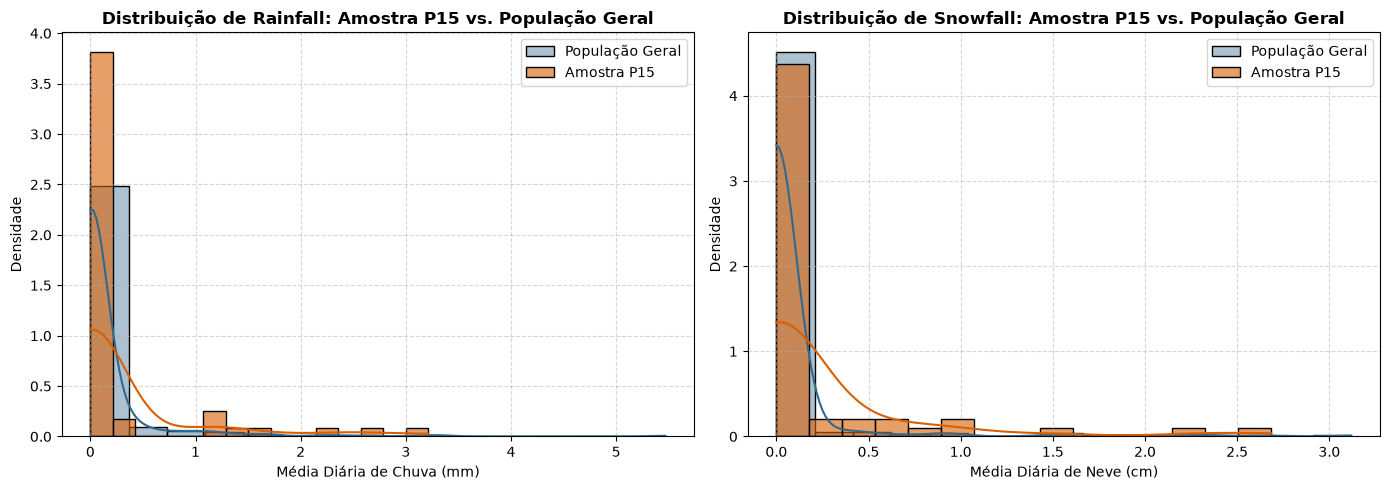

In [43]:
# Objetivo: Plotar as distribuições de Rainfall e Snowfall comparando a amostra P15 com a população geral
plt.figure(figsize=(14, 5))

# 1. Distribuição de Chuva (Rainfall)
plt.subplot(1, 2, 1)
sns.histplot(populacao['Rainfall'], color='#31688e', label='População Geral', kde=True, stat='density', bins=15, alpha=0.4)
sns.histplot(amostra_p15['Rainfall'], color='#d95f02', label='Amostra P15', kde=True, stat='density', bins=15, alpha=0.6)
plt.title('Distribuição de Rainfall: Amostra P15 vs. População Geral', fontsize=12, fontweight='bold')
plt.xlabel('Média Diária de Chuva (mm)', fontsize=10)
plt.ylabel('Densidade', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# 2. Distribuição de Neve (Snowfall)
plt.subplot(1, 2, 2)
sns.histplot(populacao['Snowfall'], color='#31688e', label='População Geral', kde=True, stat='density', bins=15, alpha=0.4)
sns.histplot(amostra_p15['Snowfall'], color='#d95f02', label='Amostra P15', kde=True, stat='density', bins=15, alpha=0.6)
plt.title('Distribuição de Snowfall: Amostra P15 vs. População Geral', fontsize=12, fontweight='bold')
plt.xlabel('Média Diária de Neve (cm)', fontsize=10)
plt.ylabel('Densidade', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### O que observei na comparação de Rainfall e Snowfall

Só esses gráficos não foram suficientes para responder as minhas dúvidas, vou explorar mais essas duas váriaveis no fechamento do colab e finalizar minhas conclusões



## Seção 8 – Análise Visual de Fechamento: Distribuição Diária e Padrões Horários

Nesta seção de fechamento, realizamos comparações visuais diretas da demanda diária acumulada e investigamos os perfis horários (0 a 23h) segundo as estações e a ocorrência de chuva e neve.


### 8.1 Distribuição da Demanda Diária por Estações, Chuva e Neve

Pergunta da análise: como a soma de aluguéis por dia se distribui quando comparamos as quatro estações e os dias com e sem precipitação (chuva e neve)?


/tmp/ipykernel_132681/1212290385.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


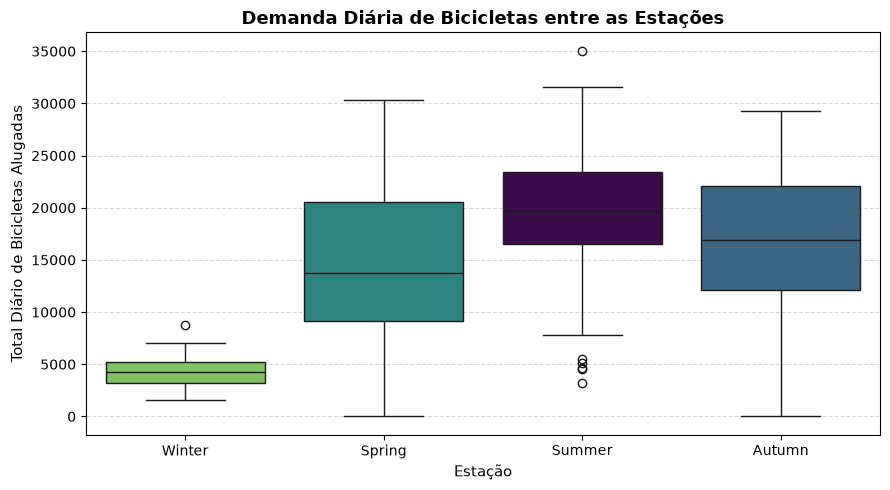

Estatísticas Descritivas da Demanda Diária por Estação:


,count,mean,std,min,25%,50%,75%,max
Seasons,,,,,,,,
Winter,90.0,4317.7,1454.0,1553.0,3209.0,4246.0,5250.5,8764.0
Spring,92.0,14151.3,7364.7,0.0,9124.2,13751.5,20583.8,30338.0
Summer,92.0,19646.8,6219.2,3207.0,16491.0,19676.5,23441.5,35061.0
Autumn,91.0,15851.0,7995.8,0.0,12089.5,16927.0,22038.5,29310.0


In [33]:
# Objetivo: Comparar a distribuição da demanda diária total entre as estações do ano e exibir tabela descritiva
daily_season = df.groupby(['Date_Parsed', 'Seasons'])['Rented_Bike_Count'].sum().reset_index()
ordem = ["Winter", "Spring", "Summer", "Autumn"]

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=daily_season,
    x="Seasons",
    y="Rented_Bike_Count",
    order=ordem,
    palette=fixed_season_palette
)
plt.title("Demanda Diária de Bicicletas entre as Estações", fontsize=13, fontweight='bold')
plt.xlabel("Estação", fontsize=11)
plt.ylabel("Total Diário de Bicicletas Alugadas", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Estatísticas Descritivas da Demanda Diária por Estação:")
display(daily_season.groupby('Seasons')['Rented_Bike_Count'].describe().round(1).reindex(ordem))


/tmp/ipykernel_132681/162911567.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


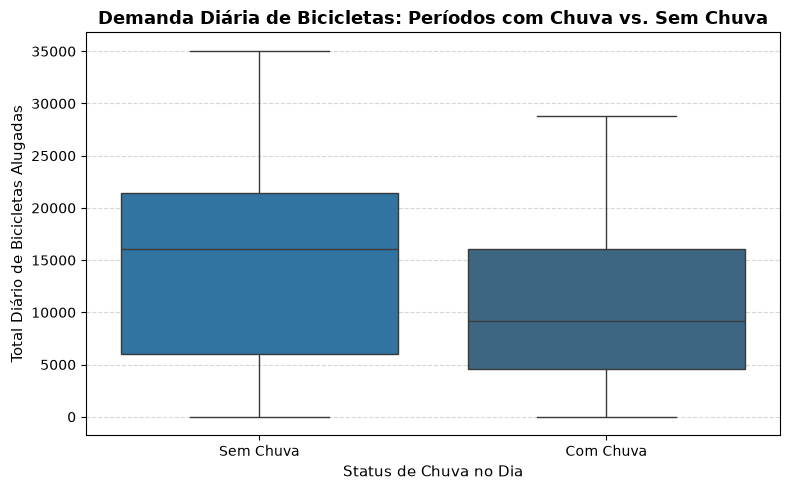

Estatísticas Descritivas da Demanda Diária por Status de Chuva:


,count,mean,std,min,25%,50%,75%,max
Rain_Status,,,,,,,,
Com Chuva,97.0,10797.6,7624.3,0.0,4583.0,9193.0,16075.0,28804.0
Sem Chuva,268.0,14526.5,8531.2,0.0,6042.8,16104.5,21400.0,35061.0


In [34]:
# Objetivo: Comparar a distribuição da demanda diária total entre dias com e sem chuva e exibir tabela descritiva
daily_rain = df.groupby('Date_Parsed').agg({'Rented_Bike_Count': 'sum', 'Rainfall': 'sum'}).reset_index()
daily_rain['Rain_Status'] = daily_rain['Rainfall'].apply(lambda x: 'Com Chuva' if x > 0 else 'Sem Chuva')

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=daily_rain,
    x="Rain_Status",
    y="Rented_Bike_Count",
    palette=['#1f78b4', '#31688e']
)
plt.title("Demanda Diária de Bicicletas: Períodos com Chuva vs. Sem Chuva", fontsize=13, fontweight='bold')
plt.xlabel("Status de Chuva no Dia", fontsize=11)
plt.ylabel("Total Diário de Bicicletas Alugadas", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Estatísticas Descritivas da Demanda Diária por Status de Chuva:")
display(daily_rain.groupby('Rain_Status')['Rented_Bike_Count'].describe().round(1))


/tmp/ipykernel_132681/2144251339.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


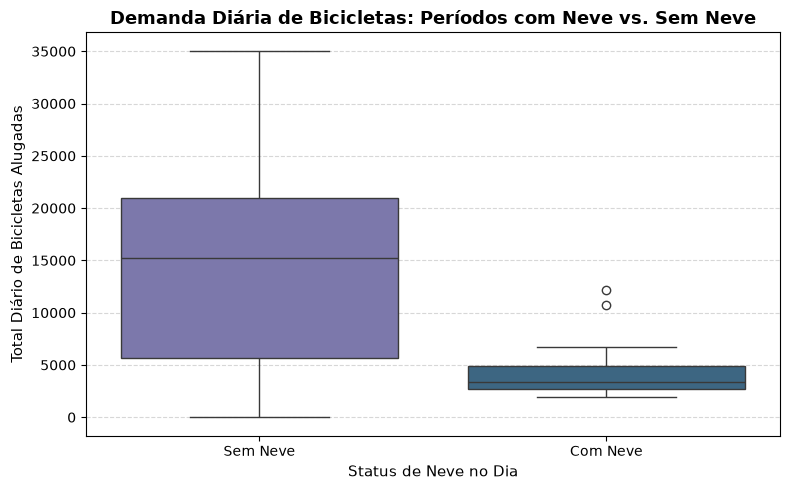

Estatísticas Descritivas da Demanda Diária por Status de Neve:


,count,mean,std,min,25%,50%,75%,max
Snow_Status,,,,,,,,
Com Neve,27.0,4265.6,2429.1,1894.0,2689.0,3417.0,4912.5,12201.0
Sem Neve,338.0,14276.0,8323.0,0.0,5630.2,15236.5,20969.2,35061.0


In [35]:
# Objetivo: Comparar a distribuição da demanda diária total entre dias com e sem neve e exibir tabela descritiva
daily_snow = df.groupby('Date_Parsed').agg({'Rented_Bike_Count': 'sum', 'Snowfall': 'sum'}).reset_index()
daily_snow['Snow_Status'] = daily_snow['Snowfall'].apply(lambda x: 'Com Neve' if x > 0 else 'Sem Neve')

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=daily_snow,
    x="Snow_Status",
    y="Rented_Bike_Count",
    palette=['#7570b3', '#31688e']
)
plt.title("Demanda Diária de Bicicletas: Períodos com Neve vs. Sem Neve", fontsize=13, fontweight='bold')
plt.xlabel("Status de Neve no Dia", fontsize=11)
plt.ylabel("Total Diário de Bicicletas Alugadas", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Estatísticas Descritivas da Demanda Diária por Status de Neve:")
display(daily_snow.groupby('Snow_Status')['Rented_Bike_Count'].describe().round(1))


### 8.2 Análise do Padrão Horário da Demanda (0 a 23h)

Pergunta da análise: de que maneira o padrão de aluguel ao longo das 24 horas do dia é modificado pelas estações do ano e pela presença de chuva ou neve?


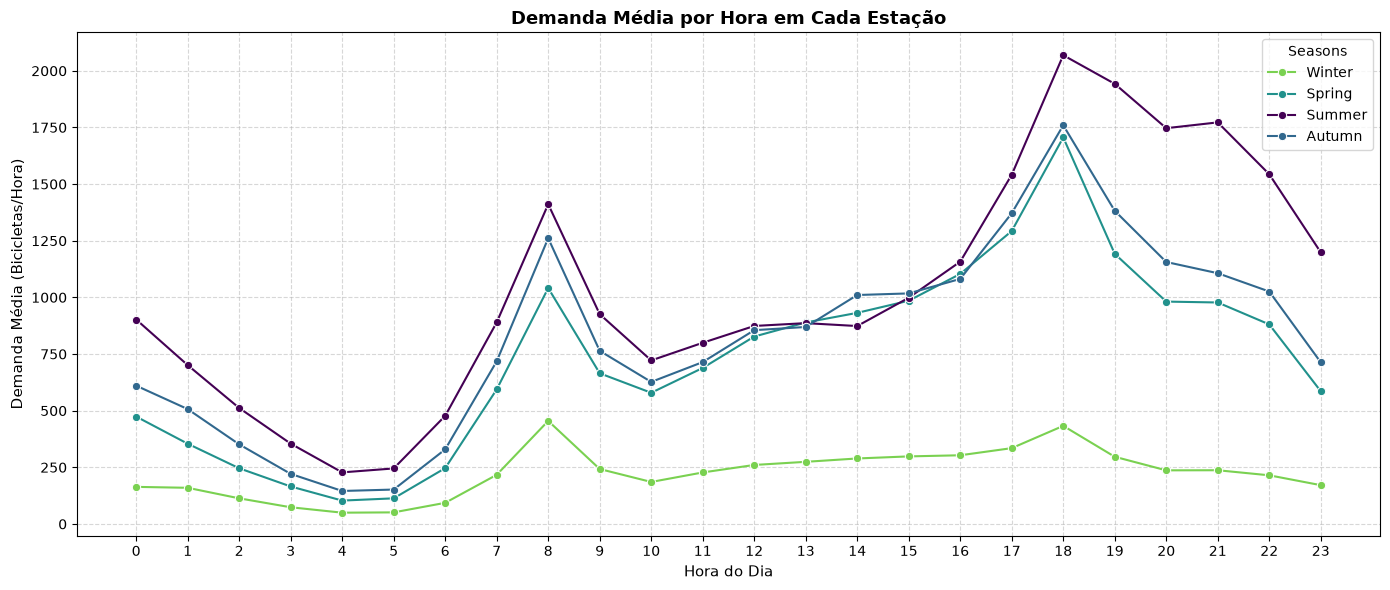

In [36]:
# Objetivo: Analisar o padrão horário de demanda de bicicletas entre as quatro estações do ano
demanda_hora_estacao = (
    df.groupby(["Hour", "Seasons"])["Rented_Bike_Count"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=demanda_hora_estacao,
    x="Hour",
    y="Rented_Bike_Count",
    hue="Seasons",
    hue_order=["Winter", "Spring", "Summer", "Autumn"],
    palette=fixed_season_palette,
    marker="o"
)
plt.title("Demanda Média por Hora em Cada Estação", fontsize=13, fontweight='bold')
plt.xlabel("Hora do Dia", fontsize=11)
plt.ylabel("Demanda Média (Bicicletas/Hora)", fontsize=11)
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


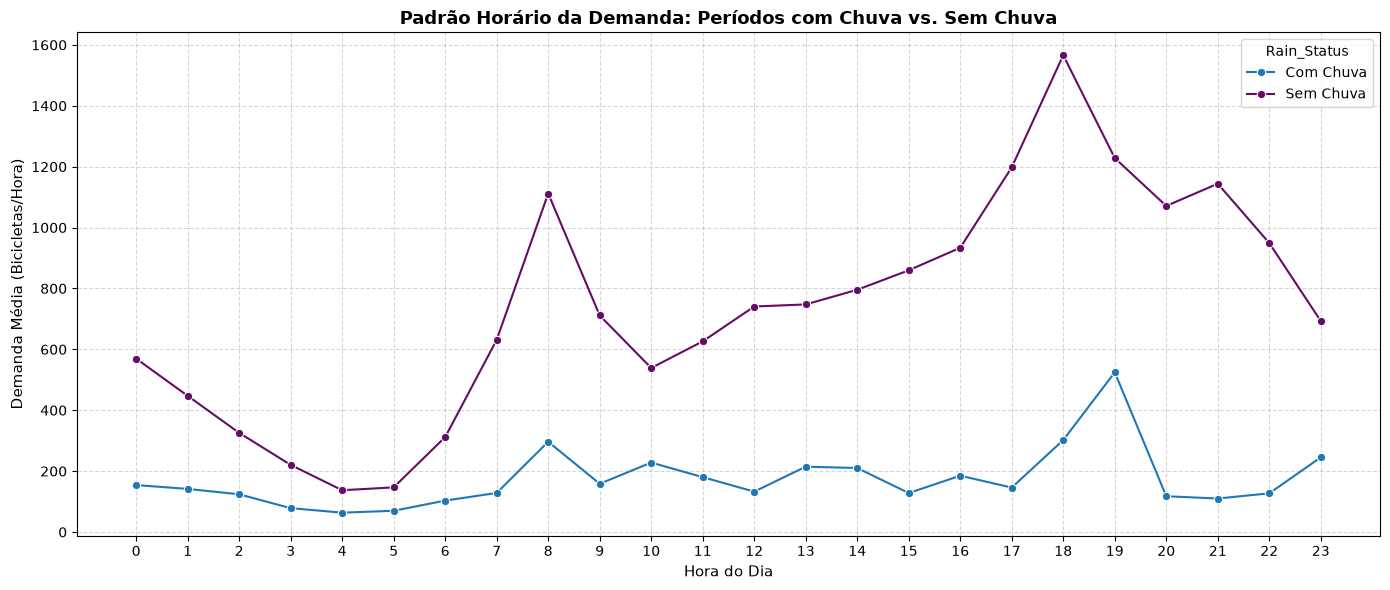

In [37]:
# Objetivo: Analisar o padrão horário de demanda comparando períodos com chuva e sem chuva
df['Rain_Status'] = df['Rainfall'].apply(lambda x: 'Com Chuva' if x > 0 else 'Sem Chuva')
demanda_hora_chuva = (
    df.groupby(["Hour", "Rain_Status"])["Rented_Bike_Count"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=demanda_hora_chuva,
    x="Hour",
    y="Rented_Bike_Count",
    hue="Rain_Status",
    palette=['#1f78b4', "#650c64"],
    marker="o"
)
plt.title("Padrão Horário da Demanda: Períodos com Chuva vs. Sem Chuva", fontsize=13, fontweight='bold')
plt.xlabel("Hora do Dia", fontsize=11)
plt.ylabel("Demanda Média (Bicicletas/Hora)", fontsize=11)
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


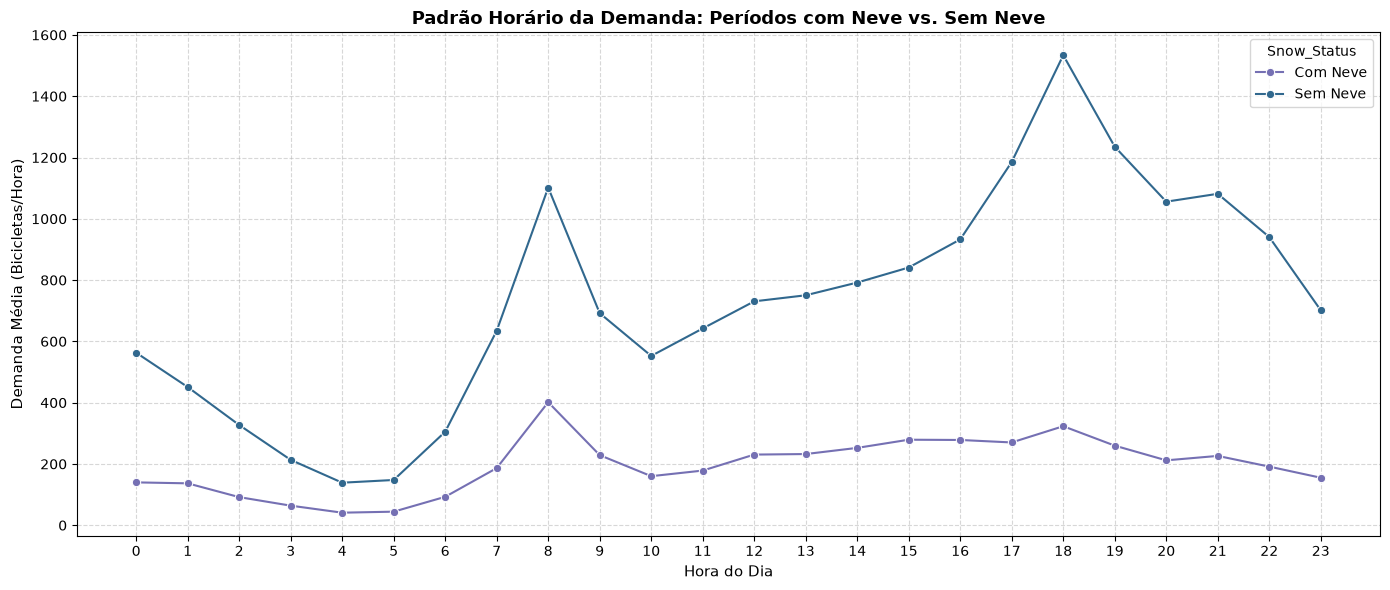

In [38]:
# Objetivo: Analisar o padrão horário de demanda comparando períodos com neve e sem neve
df['Snow_Status'] = df['Snowfall'].apply(lambda x: 'Com Neve' if x > 0 else 'Sem Neve')
demanda_hora_neve = (
    df.groupby(["Hour", "Snow_Status"])["Rented_Bike_Count"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=demanda_hora_neve,
    x="Hour",
    y="Rented_Bike_Count",
    hue="Snow_Status",
    palette=['#7570b3', '#31688e'],
    marker="o"
)
plt.title("Padrão Horário da Demanda: Períodos com Neve vs. Sem Neve", fontsize=13, fontweight='bold')
plt.xlabel("Hora do Dia", fontsize=11)
plt.ylabel("Demanda Média (Bicicletas/Hora)", fontsize=11)
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 8.3 Síntese Numérica e Conclusão Geral da Análise Exploratória (Etapa 1)

Nesta síntese, consolidamos as principais métricas que respondem formalmente à pergunta central do exame: o que faz a demanda (`Rented_Bike_Count`) subir ou cair?


In [39]:
# Objetivo: Consolidar numericamente os fatores empíricos que aceleram ou derrubam a demanda
df_ativo = df[df['Functioning_Day'] == 'Yes'].copy()

# 1. Status de Funcionamento
print("1. Status de Funcionamento do Sistema:")
display(df.groupby('Functioning_Day')['Rented_Bike_Count'].agg(Contagem='count', Media='mean', Total='sum'))

# 2. Faixas de Temperatura
faixas_temp = [-30, 0, 10, 20, 28, 50]
rotulos_temp = ['Congelante (< 0°C)', 'Frio (0 a 10°C)', 'Ameno (10 a 20°C)', 'Ideal (20 a 28°C)', 'Muito Quente (> 28°C)']
df_ativo['Faixa_Temperatura'] = pd.cut(df_ativo['Temperature'], bins=faixas_temp, labels=rotulos_temp)

print("\n2. Demanda Média por Faixa de Temperatura (Sistema Ativo):")
display(df_ativo.groupby('Faixa_Temperatura', observed=False)['Rented_Bike_Count'].agg(Media_Bikes='mean', Mediana_Bikes='median').round(1))

# 3. Penalidade de Chuva e Neve
print("\n3. Efeito de Chuva e Neve na Demanda Horária:")
media_sem_chuva = df_ativo[df_ativo['Rainfall'] == 0]['Rented_Bike_Count'].mean()
media_com_chuva = df_ativo[df_ativo['Rainfall'] > 0]['Rented_Bike_Count'].mean()
media_chuva_forte = df_ativo[df_ativo['Rainfall'] > 2]['Rented_Bike_Count'].mean()
media_sem_neve = df_ativo[df_ativo['Snowfall'] == 0]['Rented_Bike_Count'].mean()
media_com_neve = df_ativo[df_ativo['Snowfall'] > 0]['Rented_Bike_Count'].mean()

resumo_precipitacao = pd.DataFrame({
    'Condição': ['Sem Chuva', 'Com Chuva (> 0 mm)', 'Chuva Forte (> 2 mm)', 'Sem Neve', 'Com Neve (> 0 cm)'],
    'Demanda Média (bikes/h)': [media_sem_chuva, media_com_chuva, media_chuva_forte, media_sem_neve, media_com_neve]
})
display(resumo_precipitacao.round(1))

# 4. Picos de Horário por Tipo de Dia (8h e 18h)
print("\n4. Média de Aluguéis nos Horários de Pico (8h e 18h):")
picos_horarios = df_ativo[df_ativo['Hour'].isin([8, 12, 18, 22])].groupby(['Hour', 'Day_Type'])['Rented_Bike_Count'].mean().unstack().round(1)
display(picos_horarios)


1. Status de Funcionamento do Sistema:


,Contagem,Media,Total
Functioning_Day,,,
No,234,0.000000,0
Yes,6774,729.326838,4940460



2. Demanda Média por Faixa de Temperatura (Sistema Ativo):


,Media_Bikes,Mediana_Bikes
Faixa_Temperatura,,
Congelante (< 0°C),197.6,169.5
Frio (0 a 10°C),438.5,343.0
Ameno (10 a 20°C),837.5,778.0
Ideal (20 a 28°C),1137.6,1074.0
Muito Quente (> 28°C),1134.3,977.0



3. Efeito de Chuva e Neve na Demanda Horária:


,Condição,Demanda Média (bikes/h)
0,Sem Chuva,765.1
1,Com Chuva (> 0 mm),169.0
2,Chuva Forte (> 2 mm),73.9
3,Sem Neve,760.3
4,Com Neve (> 0 cm),187.9



4. Média de Aluguéis nos Horários de Pico (8h e 18h):


Day_Type,Weekday,Weekend
Hour,,
8,1327.2,431.5
12,700.7,771.4
18,1704.6,1119.0
22,989.1,832.5


### Conclusão Geral da Etapa 1: O que Faz a Demanda Subir ou Cair?

Com base em todas as etapas investigadas nesta análise exploratória, a dinâmica de aluguel de bicicletas em Seul responde a três eixos determinantes:

#### 1. Condição Operacional Exógena (Filtro Zero)
- `Functioning_Day == 'No'`: o sistema esteve inoperante em 234 horas do ano, registrando rigorosamente `0` aluguéis. Isso explica os vales zerados isolados na série temporal diária, decorrentes de indisponibilidade do serviço e não de desinteresse dos usuários.

#### 2. Fatores de Alta da Demanda (Aceleradores)
- `Temperature`: é o preditor meteorológico contínuo mais forte. Em temperaturas negativas (< 0 °C), a média é de ~198 bikes/hora. Quando o clima atinge a faixa ideal de conforto (20 a 28 °C), a média atinge ~1.138 bikes/hora (um salto de quase seis vezes).
- `Seasons`: Verão (`Summer`) e Outono (`Autumn`) lideram os aluguéis diários totais (medianas diárias de ~19.676 e ~16.927 bikes/dia), impulsionados por temperaturas agradáveis e radiação solar, enquanto o Inverno (`Winter`) derruba a mediana diária para apenas ~4.246 bikes/dia.
- `Hour` e `Day_Type`: nos dias úteis (`Weekday`), a demanda é impulsionada pelos horários de pico de trabalho/estudo, atingindo médias acentuadas às 08h (~1.327 bikes/hora) e às 18h (~1.705 bikes/hora). Nos finais de semana (`Weekend`), o uso concentra-se no lazer com perfil suave ao longo da tarde.

#### 3. Fatores de Queda Brusca da Demanda (Penalidades Severas)
- `Rainfall`: a chuva é o principal fator inibidor imediato. Qualquer presença de chuva (> 0 mm) reduz a média horária de 765 para 169 bikes/hora (queda de ~78%). Precipitações moderadas a fortes (> 2 mm) colapsam a demanda para ~74 bikes/hora (queda superior a 90%). O mesmo efeito é nítido no perfil horário: mesmo nos picos das 18h, a chuva achata a curva drasticamente.
- `Snowfall`: a neve derruba a média horária para ~188 bikes/hora e a mediana diária para ~3.417 bikes/dia, operando em sinergia com o frio intenso do inverno.
- Confirmação pela Subamostra (P15): os dias que compõem os 15% de menor demanda do ano registraram média de chuva três vezes superior (0,28 mm vs. 0,11 mm) e de neve quatro vezes superior (0,22 cm vs. 0,05 cm) ao restante do ano. Isso resolve o ponto levantado no início do trabalho: as quedas anômalas em dias de estações quentes são causadas por tempestades e chuvas severas.

#### 4. Variáveis Mais Promissoras para as Próximas Etapas (Hipóteses e Modelagem Linear)
- **Meteorológicas:** `Temperature`, `Rainfall`, `Snowfall`, `Solar_Radiation` e `Humidity`.
- **Calendário e Tempo:** `Hour` (com codificação cíclica ou dummy para capturar os picos das 8h e 18h), `Seasons` e a interação entre `Hour` e `Day_Type`.
- **Recomendações Estatísticas:** tratar a multicolinearidade severa entre `Temperature` e `Dew_Point_Temperature`, considerar transformações na variável resposta (como logarítmica) para lidar com a assimetria positiva, e separar o tratamento de dias inativos (`Functioning_Day == 'No'`).
